In [1]:
import numpy as np
import pickle

from particle_filter.simulations import system_simulation

from particle_filter.filtering_algorithms.particle_filter import BootstrapParticleFilter, AuxiliaryParticleFilter

from particle_filter.models.noise import GaussianNoise
from particle_filter.models.transition import AdditiveTransitionModel
from particle_filter.models.observation import AdditiveObservationModel

from particle_filter.plots.plot_results import plot_results
from particle_filter.plots.plot_comparisons import plot_comparisons
from particle_filter.plots.plot_EES import plot_ESS
from particle_filter.plots.plot_weights import plot_sorted_weights
from particle_filter.plots.plot_particles_diversity import plot_particles_divessity

En este notebook se van a comparar las diferentes técnicas de remuestreo. Dentro de las numerosas opciones que hay, se han elegido implementar las técnicas $Multinomial$, $Systematic$ y $Residual$.

Para esta comparación, se ha elegido el siguiente sistema unidimensional:

- Ecuación de transición:

$$
x_t = \phi \cdot x_{t-1} + w_t,\;\;\; w_t \sim \mathcal{N}(0, 1)
$$

con $\phi=0.95$.

- Ecuación de observación:

$$
y_t = \frac{x_{t}^2}{2} + v_t,\;\;\; v_t \sim \mathcal{N}(0, 1)
$$

Esta ecuación de la observación implica que, condicionado a $x_t$:

$$
p(y_t \mid x_t) = \mathcal{N}\left( y_t ; \frac{x_t^2}{2},1 \right)
$$

Si se observa $y_t=4$, los valores de $x_t$ la verosimilitud puede tener dos máximos: uno alrededor de $+2.83$ y otro alrededor de $-2.83$.

El valor de $\phi=0.95$ hace que el estado tenga bastante persistencia. Si se tiene que $x_{t-1}>0$, la predicción tenderá a estar centrada en valores positivos y puede eliminar el modo negativo. Pero si la incertidumbre predictiva es suficientemente grande, la obervación puede generar dos posibilidades: una positiva y otra negativa. Entonces, la dinámica favorece la continuidad del signo, mientras que la observación pierde la información del signo.

Por lo tanto, si la distribución predicitiva $p(x_t \mid y_{1:t-1})$ está muy concentrada alrededor de un valor positivo, la posterior probablemente será unimodal. En cambio, si la predicción es lo suficientemente dispersa y $y_t$ es suficientemente grande, la observación puede porducir una posterior bimodal. Si $y_t$ es pequeño, los dos máximos $\pm \sqrt{2y_t}$ están próximos y pueden acabar formando un pico alredeor de cero.


In [2]:
phi = 0.95

def f(x):

    return phi * x

def h(x):

    return (x * x) / 2

In [ ]:
# Ruidos gaussianos
Q = np.diag( [1.0] ) # ruido transición
R = np.array( [1.0] ) # ruido observación

noise_transition = GaussianNoise(Q)
noise_observation = GaussianNoise(R)

In [4]:
# Modelos
transition_mod = AdditiveTransitionModel(f, noise_transition) # modelo de transicion
observation_mod = AdditiveObservationModel(h, noise_observation) # modelo de observación

In [5]:
with open("exp_14.pkl", "rb") as file:
    simulation_data = pickle.load(file)


In [2]:
n_simulations = 10
n_repetitions  = 1

mcmc_cov = np.array( [1.0] )

T = 100

results = {
    "Auxiliary PF Systematic": [],
    "Auxiliary PF Multinomial": [],
    "Auxiliary PF Residual": []
}

for i in range(n_simulations):

    x0 = np.array([0.0])

    # Simular el sistema
    #x_true, y_obs = system_simulation(transition_mod, observation_mod, x0, T)

    # Tomar resultados
    x_true = simulation_data["Bootstrap PF Multinomial"][i]["x_true"]
    y_obs = simulation_data["Bootstrap PF Multinomial"][i]["y_obs"]

    for j in range(n_repetitions):

        # Muestreo sistematico
        apf = AuxiliaryParticleFilter(1000, transition_mod, observation_mod)
        apf.initialize(mean=np.array([0.0]), cov=np.array([4.0]))
        est_apf_sys = apf.run_filter(y_obs, 0.5 * apf.N, 1, mcmc_cov)

        results["Auxiliary PF Systematic"].append({
            "n_simulation":i,
            "n_filter":j,
            "x_true": x_true,
            "y_obs": y_obs,
            "est": est_apf_sys 
        })

        # Muestreo multinomial
        apf = AuxiliaryParticleFilter(1000, transition_mod, observation_mod, "multinomial")
        apf.initialize(mean=np.array([0.0]), cov=np.array([4.0]))
        est_apf_mult = apf.run_filter(y_obs, 0.5 * apf.N, 1, mcmc_cov)

        results["Auxiliary PF Multinomial"].append({
            "n_simulation":i,
            "n_filter":j,
            "x_true": x_true,
            "y_obs": y_obs,
            "est": est_apf_mult 
        })

        # Muestreo residual
        apf = AuxiliaryParticleFilter(1000, transition_mod, observation_mod, "residual")
        apf.initialize(mean=np.array([0.0]), cov=np.array([4.0]))
        est_apf_res = apf.run_filter(y_obs, 0.5 * apf.N, 1, mcmc_cov)

        results["Auxiliary PF Residual"].append({
            "n_simulation":i,
            "n_filter":j,
            "x_true": x_true,
            "y_obs": y_obs,
            "est": est_apf_res 
        })

    print(f"Simluacion {i} finalizada.")


with open("exp_25.pkl", "wb") as file:
    pickle.dump(results, file)

NameError: name 'simulation_data' is not defined

### 1. Comparación métodos de remuestreo

En esta primera parte se comparan los distintos tipos de remuetreo (Multinomial, Sistemático y Residual) para distintos números de partículas. 

Para comparar los métodos se va a calcular el número efectivo de ancestros. Esto es, el número de partículas distintas que son escogidas para crear copias. Este parámetro se calcula mediante:

$$
N_{eff,anc} =\frac{1}{\sum \left( \frac{n_i}{N} \right)^2}

$$

donde $n_i$ es el número de descendientes creados a partir del ancestro $i$; es decir, el número de veces que la partícula $i$ es escogida para crear un descendiente. 

Este número se calcula como la media obtenida a partir de 10 simulaciones.

En primera lugar se tratan los resultados para un fitlro de tipo Bootstrap.

In [2]:
with open("exp_14.pkl", "rb") as file:
    results_bpf_50_N = pickle.load(file)

with open("exp_15.pkl", "rb") as file:
    results_bpf_100_N = pickle.load(file)

with open("exp_16.pkl", "rb") as file:
    results_bpf_500_N = pickle.load(file)

with open("exp_17.pkl", "rb") as file:
    results_bpf_1000_N = pickle.load(file)

with open("exp_22.pkl", "rb") as file:
    results_bpf_5000_N = pickle.load(file)    

In [3]:
from N_eff_ancestors import average_N_eff_anc

N_particles = [50, 100, 500, 1000, 5000]
N_simulations = 10

results = {
    50: results_bpf_50_N,
    100: results_bpf_100_N,
    500: results_bpf_500_N,
    1000: results_bpf_1000_N,
    5000: results_bpf_5000_N
}

bpf_mult = dict.fromkeys(N_particles)
bpf_sys = dict.fromkeys(N_particles)
bpf_res = dict.fromkeys(N_particles)

for N_part in N_particles:

    mean_mult, std_mult, mean_sys, std_sys, mean_res, std_res = average_N_eff_anc(results[N_part], N_simulations, N_part, "Bootstrap")

    bpf_mult[N_part] = {"mean": mean_mult, "std": std_mult}
    bpf_sys[N_part] = {"mean": mean_sys, "std": std_sys}
    bpf_res[N_part] = {"mean": mean_res, "std": std_res}


for N_part in N_particles:
    print(f"Multiomial con {N_part} partículas: {bpf_mult[N_part]["mean"]} +/- {bpf_mult[N_part]["std"]}")
    print(f"Systematic con {N_part} partículas: {bpf_sys[N_part]["mean"]} +/- {bpf_sys[N_part]["std"]}")
    print(f"Residual con {N_part} partículas: {bpf_res[N_part]["mean"]} +/- {bpf_res[N_part]["std"]}")
    print("")


Multiomial con 50 partículas: 0.23341518785890886 +/- 0.01774622570320428
Systematic con 50 partículas: 0.2986380229285651 +/- 0.022949382626578196
Residual con 50 partículas: 0.28404737561560667 +/- 0.025280761335234936

Multiomial con 100 partículas: 0.23050370062179426 +/- 0.018469868117266544
Systematic con 100 partículas: 0.29676020738989084 +/- 0.026541429473743605
Residual con 100 partículas: 0.2786580451138775 +/- 0.023306695650861964

Multiomial con 500 partículas: 0.2269731327719143 +/- 0.01711485328231204
Systematic con 500 partículas: 0.29962178643751836 +/- 0.023933367236159978
Residual con 500 partículas: 0.2819269356497027 +/- 0.02243512111666494

Multiomial con 1000 partículas: 0.22890429725958433 +/- 0.015374216535707535
Systematic con 1000 partículas: 0.29535060451875716 +/- 0.02321190018569393
Residual con 1000 partículas: 0.2780744813922064 +/- 0.02242357058327327

Multiomial con 5000 partículas: 0.22639716434699603 +/- 0.015624867379763095
Systematic con 5000 partí

(<Figure size 800x600 with 1 Axes>,
 <Axes: xlabel='Numero particulas N', ylabel='Numero efectivo ancestros'>)

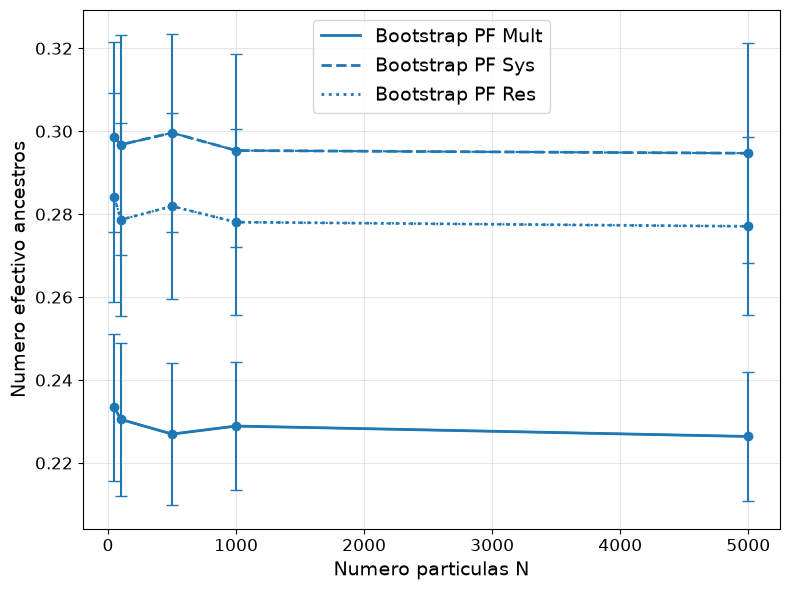

In [4]:
bpf_mult_means = [value["mean"] for value in bpf_mult.values()]
bpf_mult_std = [value["std"] for value in bpf_mult.values()]

bpf_sys_means = [value["mean"] for value in bpf_sys.values()]
bpf_sys_std = [value["std"] for value in bpf_sys.values()]

bpf_res_means = [value["mean"] for value in bpf_res.values()]
bpf_res_std = [value["std"] for value in bpf_res.values()]


plot_comparisons(
    {
        "Bootstrap PF Mult": {"Numero particulas N": N_particles, "Numero efectivo ancestros": bpf_mult_means, "Numero efectivo ancestros_errorbars": bpf_mult_std },
        "Bootstrap PF Sys": {"Numero particulas N": N_particles, "Numero efectivo ancestros": bpf_sys_means, "Numero efectivo ancestros_errorbars": bpf_sys_std },
        "Bootstrap PF Res": {"Numero particulas N": N_particles, "Numero efectivo ancestros": bpf_res_means, "Numero efectivo ancestros_errorbars": bpf_res_std },
    }, "Numero particulas N", "Numero efectivo ancestros", "Comparación del número efectivo de ancestro según el número de partículas", True
)

En general, se tiene que cada vez se realiza un remuestreo, el método $\textit{Multinomial}$ tiene un menor número de ancestros efectivos. En este método se elige una partícula $i$ con probabilidad $w_i$. En promedio, cada partícula debería ser escogida un número de veces $\mathbb{E}[N_i]=Nw_i$. El método $\textit{Multinomial}$ permite flucutacoines alrededor del número esperado de descendientes provocando que una partícula pueda aparecer de manera excesiva o que otra partícula que debería aparecer desapareciera.

En cambio, los métodos $\textit{Systematic}$ y $\textit{Residual}$ reducen el efecto del azar, controlando en mayor medida el númeo de duplicaciones que una partícula puede dar.

Esto implica que al realizar el remuestreo, la mayor varianza del método $\textit{Multinomial}$ puede conllevar excesivas duplicaciones o desapariciones aleatorias, lo que se puede traducir en una menor diversidad.

Ahora, se realiza el mismo proceso para la versión Auxiliary. 

In [3]:
with open("exp_18.pkl", "rb") as file:
    results_apf_50_N = pickle.load(file)

with open("exp_19.pkl", "rb") as file:
    results_apf_100_N = pickle.load(file)

with open("exp_20.pkl", "rb") as file:
    results_apf_500_N = pickle.load(file)

with open("exp_21.pkl", "rb") as file:
    results_apf_1000_N = pickle.load(file)

with open("exp_23.pkl", "rb") as file:
    results_apf_5000_N = pickle.load(file)

In [7]:
from N_eff_ancestors import average_N_eff_anc

N_particles = [50, 100, 500, 1000, 5000]
N_simulations = 10

results = {
    50: results_apf_50_N,
    100: results_apf_100_N,
    500: results_apf_500_N,
    1000: results_apf_1000_N,
    5000: results_apf_5000_N
}

apf_mult = dict.fromkeys(N_particles)
apf_sys = dict.fromkeys(N_particles)
apf_res = dict.fromkeys(N_particles)

for N_part in N_particles:

    mean_mult, std_mult, mean_sys, std_sys, mean_res, std_res = average_N_eff_anc(results[N_part], N_simulations, N_part, "Auxiliary")

    apf_mult[N_part] = {"mean": mean_mult, "std": std_mult}
    apf_sys[N_part] = {"mean": mean_sys, "std": std_sys}
    apf_res[N_part] = {"mean": mean_res, "std": std_res}


for N_part in N_particles:
    print(f"Multiomial con {N_part} partículas: {apf_mult[N_part]["mean"]} +/- {apf_mult[N_part]["std"]}")
    print(f"Systematic con {N_part} partículas: {apf_sys[N_part]["mean"]} +/- {apf_sys[N_part]["std"]}")
    print(f"Residual con {N_part} partículas: {apf_res[N_part]["mean"]} +/- {apf_res[N_part]["std"]}")
    print("")

Multiomial con 50 partículas: 0.1899613485124036 +/- 0.020232510557503525
Systematic con 50 partículas: 0.23240038614164563 +/- 0.024313819844924287
Residual con 50 partículas: 0.2346267491069305 +/- 0.023089252438918653

Multiomial con 100 partículas: 0.18452690537956196 +/- 0.014552201372384246
Systematic con 100 partículas: 0.22143750592985248 +/- 0.032948853317039895
Residual con 100 partículas: 0.20808491467331294 +/- 0.027034333919139706

Multiomial con 500 partículas: 0.15624542499579003 +/- 0.020487929284803575
Systematic con 500 partículas: 0.19567780750385527 +/- 0.030465497932230533
Residual con 500 partículas: 0.1829126389090894 +/- 0.02442094439315791

Multiomial con 1000 partículas: 0.14821228671442124 +/- 0.018255986406030777
Systematic con 1000 partículas: 0.1887805287583854 +/- 0.02418362233800802
Residual con 1000 partículas: 0.1746839498511114 +/- 0.03385824422586736

Multiomial con 5000 partículas: 0.13585600924179425 +/- 0.018302097896693684
Systematic con 5000 par

(<Figure size 800x600 with 1 Axes>,
 <Axes: xlabel='Numero particulas N', ylabel='Numero efectivo ancestros'>)

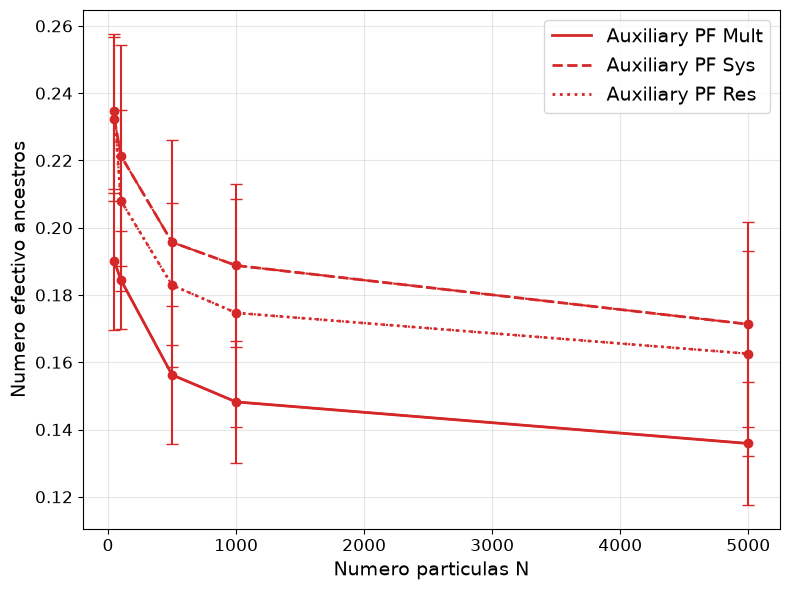

In [8]:
mult_means = [value["mean"] for value in apf_mult.values()]
mult_std = [value["std"] for value in apf_mult.values()]

sys_means = [value["mean"] for value in apf_sys.values()]
sys_std = [value["std"] for value in apf_sys.values()]

res_means = [value["mean"] for value in apf_res.values()]
res_std = [value["std"] for value in apf_res.values()]


plot_comparisons(
    {
        "Auxiliary PF Mult": {"Numero particulas N": N_particles, "Numero efectivo ancestros": mult_means, "Numero efectivo ancestros_errorbars": mult_std },
        "Auxiliary PF Sys": {"Numero particulas N": N_particles, "Numero efectivo ancestros": sys_means, "Numero efectivo ancestros_errorbars": sys_std },
        "Auxiliary PF Res": {"Numero particulas N": N_particles, "Numero efectivo ancestros": res_means, "Numero efectivo ancestros_errorbars": res_std },
    }, "Numero particulas N", "Numero efectivo ancestros", "Comparación del número efectivo de ancestro según el número de partículas", True
)

En este caso, se tiene el mismo comportamiento: el número efectivo de ancestros para el método $\textit{Multinomial}$ es, en general, menor en comparación con los demás métodos. Además, al igual que el caso Bootstrap, el método con mejor el el remuestreo $\textit{Sytematic}$.  

Por último, se van a comparar los resultado entre las dos versiones del filtro.

(<Figure size 800x600 with 1 Axes>,
 <Axes: xlabel='Numero particulas', ylabel='Numero efectivo ancestros'>)

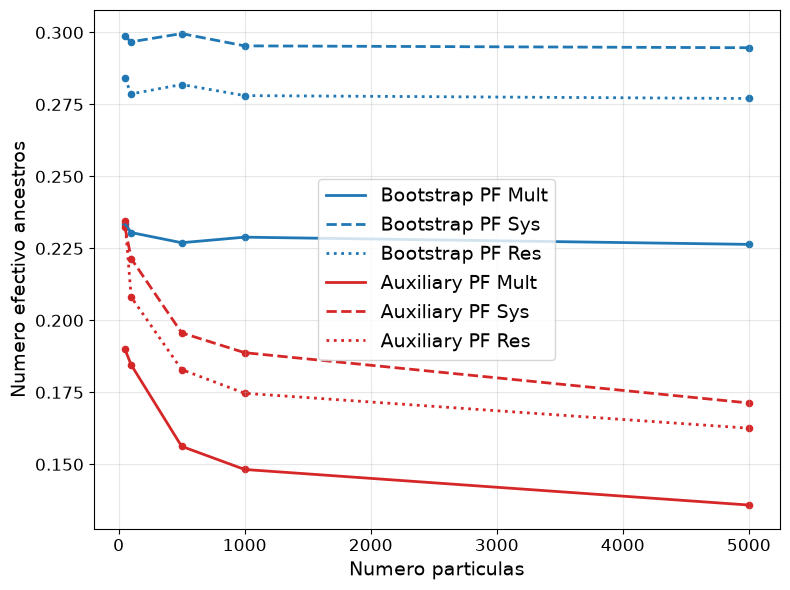

In [10]:
plot_comparisons(
    {
        "Bootstrap PF Mult": {"Numero particulas": N_particles, "Numero efectivo ancestros": bpf_mult_means, "Numero efectivo ancestros_errorbars": bpf_mult_std },
        "Bootstrap PF Sys": {"Numero particulas": N_particles, "Numero efectivo ancestros": bpf_sys_means, "Numero efectivo ancestros_errorbars": bpf_sys_std },
        "Bootstrap PF Res": {"Numero particulas": N_particles, "Numero efectivo ancestros": bpf_res_means, "Numero efectivo ancestros_errorbars": bpf_res_std },
        "Auxiliary PF Mult": {"Numero particulas": N_particles, "Numero efectivo ancestros": mult_means, "Numero efectivo ancestros_errorbars": mult_std },
        "Auxiliary PF Sys": {"Numero particulas": N_particles, "Numero efectivo ancestros": sys_means, "Numero efectivo ancestros_errorbars": sys_std },
        "Auxiliary PF Res": {"Numero particulas": N_particles, "Numero efectivo ancestros": res_means, "Numero efectivo ancestros_errorbars": res_std },
    }, "Numero particulas", "Numero efectivo ancestros", "método de remuestreo", False
)

En esta gráfica se observa que en el caso del Auxiliary, el número efectivo de ancestros es, para todos los métodos de remuestreo, menor que el Bootstrap. La razón de esta diferencia radica en el paso predictivo que realiza el Auxiliary para explicar la observación $y_{k}$. Esto provoca que los pesos auxiliares correspondientes a está selección estén más concentrados que los pesos originales: si unas pocas partículas tienen una predicción mucho más compatible con la observación, el APF les asigna una mayor probabilidad. De esta manera, se reduce la diversidad para poder realizar una selección más informada. El BPF, al no realizar la selección auxiliar, puede mantener mayor diversidad.

A continuación, se muestra las consecuencias el número efectivo de partículas y en su diversidad para el caso de 1000 partículas. 

In [13]:
from average_results import average_results

N_simul = 10
N_filt = 1
T = 100

bpf_sys = average_results(results_bpf_1000_N["Bootstrap PF Systematic"], N_simul, N_filt, T)
bpf_mult = average_results(results_bpf_1000_N["Bootstrap PF Multinomial"], N_simul, N_filt, T)
bpf_res = average_results(results_bpf_1000_N["Bootstrap PF Residual"], N_simul, N_filt, T)

apf_sys = average_results(results_apf_1000_N["Auxiliary PF Systematic"], N_simul, N_filt, T)
apf_mult = average_results(results_apf_1000_N["Auxiliary PF Multinomial"], N_simul, N_filt, T)
apf_res = average_results(results_apf_1000_N["Auxiliary PF Residual"], N_simul, N_filt, T)

c:\Users\usuario\Desktop\Particle_Filter\.venv\Lib\site-packages\numpy\_core\_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
c:\Users\usuario\Desktop\Particle_Filter\.venv\Lib\site-packages\numpy\_core\_methods.py:211: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


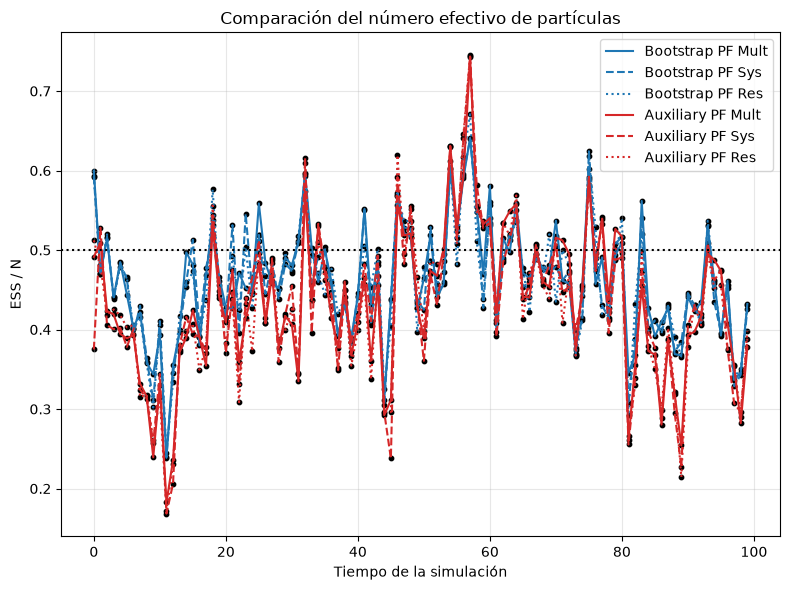

In [10]:
from plot_ess import plot_ESS

plot_ESS({
    "Bootstrap PF Mult": bpf_mult["mean"]["ESS"],
    "Bootstrap PF Sys": bpf_sys["mean"]["ESS"],
    "Bootstrap PF Res": bpf_res["mean"]["ESS"],
    "Auxiliary PF Mult": apf_mult["mean"]["ESS"],
    "Auxiliary PF Sys": apf_sys["mean"]["ESS"],
    "Auxiliary PF Res": apf_res["mean"]["ESS"],
}, 1000)

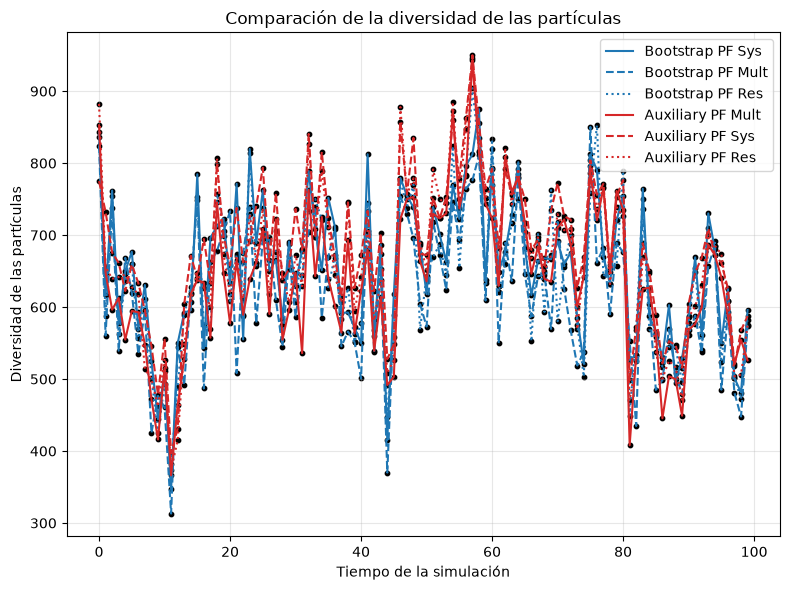

In [59]:
plot_particles_divessity({
    "Bootstrap PF Sys": bpf_sys["mean"]["Unique_particles"],
    "Bootstrap PF Mult": bpf_mult["mean"]["Unique_particles"],
    "Bootstrap PF Res": bpf_res["mean"]["Unique_particles"],
    "Auxiliary PF Mult": apf_mult["mean"]["Unique_particles"],
    "Auxiliary PF Sys": apf_sys["mean"]["Unique_particles"],
    "Auxiliary PF Res": apf_res["mean"]["Unique_particles"]    
})


NO SE APRECIA MUCHA DIFERENCIA

### 2. Comparación rendimiento

In [14]:
N_particles =[50, 100, 500, 1000, 5000]
N_simulations = 10
N_filter = 1
T_simul = 100

results_bpf = {
    50: results_bpf_50_N,
    100: results_bpf_100_N,
    500: results_bpf_500_N,
    1000: results_bpf_1000_N,
    5000: results_bpf_5000_N
}

results_apf = {
    50: results_apf_50_N,
    100: results_apf_100_N,
    500: results_apf_500_N,
    1000: results_apf_1000_N,
    5000: results_apf_5000_N
}

mean_results_bpf_mult = dict.fromkeys(N_particles)
mean_results_bpf_sys = dict.fromkeys(N_particles)
mean_results_bpf_res = dict.fromkeys(N_particles)
mean_results_apf_mult = dict.fromkeys(N_particles)
mean_results_apf_sys = dict.fromkeys(N_particles)
mean_results_apf_res = dict.fromkeys(N_particles)

for N_part in N_particles:

    bpf_mult = average_results(results_bpf[N_part]["Bootstrap PF Multinomial"], N_simulations, N_filter, T_simul)
    bpf_sys = average_results(results_bpf[N_part]["Bootstrap PF Systematic"], N_simulations, N_filter, T_simul)
    bpf_res = average_results(results_bpf[N_part]["Bootstrap PF Residual"], N_simulations, N_filter, T_simul)

    mean_results_bpf_mult[N_part] = bpf_mult
    mean_results_bpf_sys[N_part] = bpf_sys
    mean_results_bpf_res[N_part] = bpf_res

    apf_mult = average_results(results_apf[N_part]["Auxiliary PF Multinomial"], N_simulations, N_filter, T_simul)
    apf_sys = average_results(results_apf[N_part]["Auxiliary PF Systematic"], N_simulations, N_filter, T_simul)
    apf_res = average_results(results_apf[N_part]["Auxiliary PF Residual"], N_simulations, N_filter, T_simul)

    mean_results_apf_mult[N_part] = apf_mult
    mean_results_apf_sys[N_part] = apf_sys
    mean_results_apf_res[N_part] = apf_res



(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'metodo de remuestreo'}, xlabel='Numero particulas', ylabel='RMSE'>)

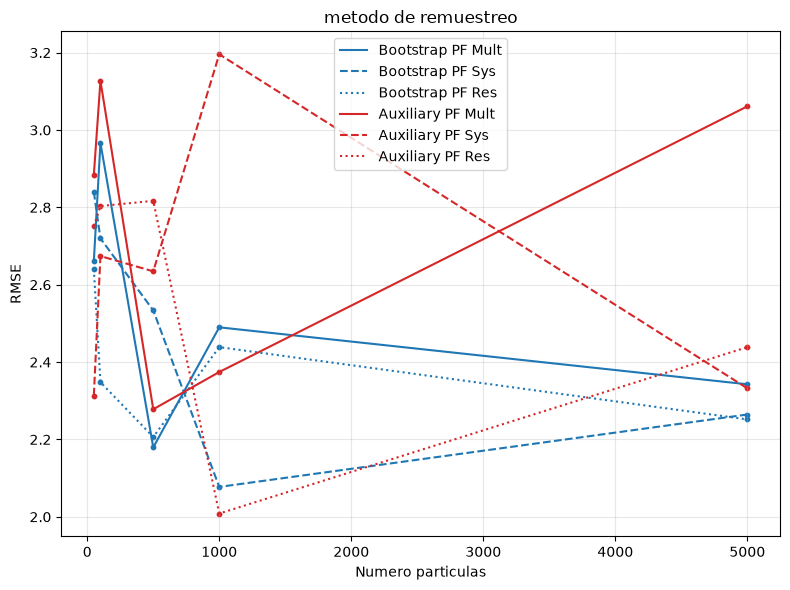

In [11]:
plot_comparisons(
    {
        "Bootstrap PF Mult": {"Numero particulas": N_particles, "RMSE": [ mean_results_bpf_mult[N_part]["mean"]["RMSE"] for N_part in N_particles ]},
        "Bootstrap PF Sys": {"Numero particulas": N_particles, "RMSE": [ mean_results_bpf_sys[N_part]["mean"]["RMSE"] for N_part in N_particles ]},
        "Bootstrap PF Res": {"Numero particulas": N_particles, "RMSE": [ mean_results_bpf_res[N_part]["mean"]["RMSE"] for N_part in N_particles ]},
        "Auxiliary PF Mult": {"Numero particulas": N_particles, "RMSE": [ mean_results_apf_mult[N_part]["mean"]["RMSE"] for N_part in N_particles ]},
        "Auxiliary PF Sys": {"Numero particulas": N_particles, "RMSE": [ mean_results_apf_sys[N_part]["mean"]["RMSE"] for N_part in N_particles ]},
        "Auxiliary PF Res": {"Numero particulas": N_particles, "RMSE": [ mean_results_apf_res[N_part]["mean"]["RMSE"] for N_part in N_particles ]},

    }, "Numero particulas", "RMSE", "metodo de remuestreo"
)

(<Figure size 800x600 with 1 Axes>,
 <Axes: xlabel='Número de partículas N', ylabel='Loglikelihood'>)

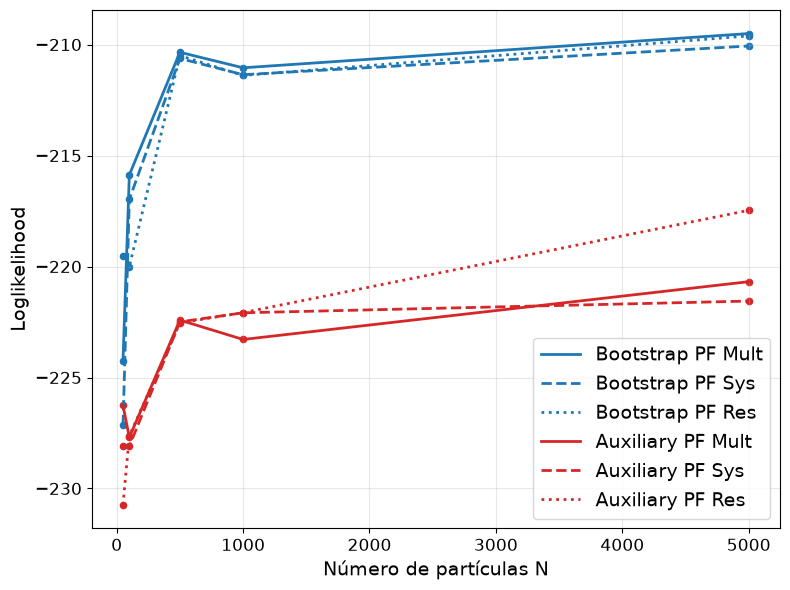

In [15]:
plot_comparisons(
    {
        "Bootstrap PF Mult": {"Número de partículas N": N_particles, "Loglikelihood": [ mean_results_bpf_mult[N_part]["mean"]["Loglikelihood"] for N_part in N_particles ]},
        "Bootstrap PF Sys": {"Número de partículas N": N_particles, "Loglikelihood": [ mean_results_bpf_sys[N_part]["mean"]["Loglikelihood"] for N_part in N_particles ]},
        "Bootstrap PF Res": {"Número de partículas N": N_particles, "Loglikelihood": [ mean_results_bpf_res[N_part]["mean"]["Loglikelihood"] for N_part in N_particles ]},
        "Auxiliary PF Mult": {"Número de partículas N": N_particles, "Loglikelihood": [ mean_results_apf_mult[N_part]["mean"]["Loglikelihood"] for N_part in N_particles ]},
        "Auxiliary PF Sys": {"Número de partículas N": N_particles, "Loglikelihood": [ mean_results_apf_sys[N_part]["mean"]["Loglikelihood"] for N_part in N_particles ]},
        "Auxiliary PF Res": {"Número de partículas N": N_particles, "Loglikelihood": [ mean_results_apf_res[N_part]["mean"]["Loglikelihood"] for N_part in N_particles ]},

    }, "Número de partículas N", "Loglikelihood", "Comparación de la logverosimilitud según el número de partículas"
)

La diferencia entre las dos métricas se explica por lo expuesto anteriormente. El RMSE es una estadística puntual y, el filtrado funcionará bien si acierta la moda en la que se encuentra el estado. En cambio, dado que en el caso del BPF, se mantiene una distribución de partículas más adecuada, se tiene un mejor rendimiento para la log-verosimilitud. 

A continuación, se representa la probabilidad de tener un estado positivo. La idea es comprobar si la distribución de las partículas conservan las dos posibles modas del modelo.

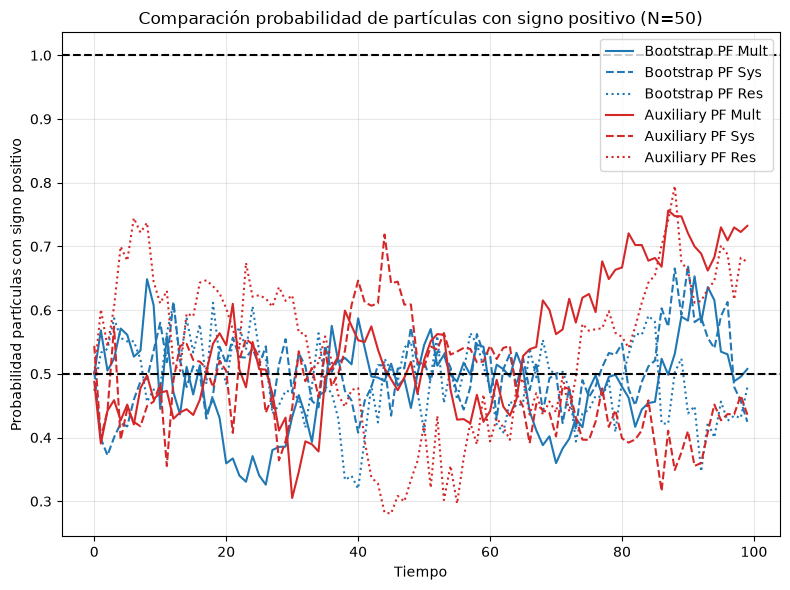

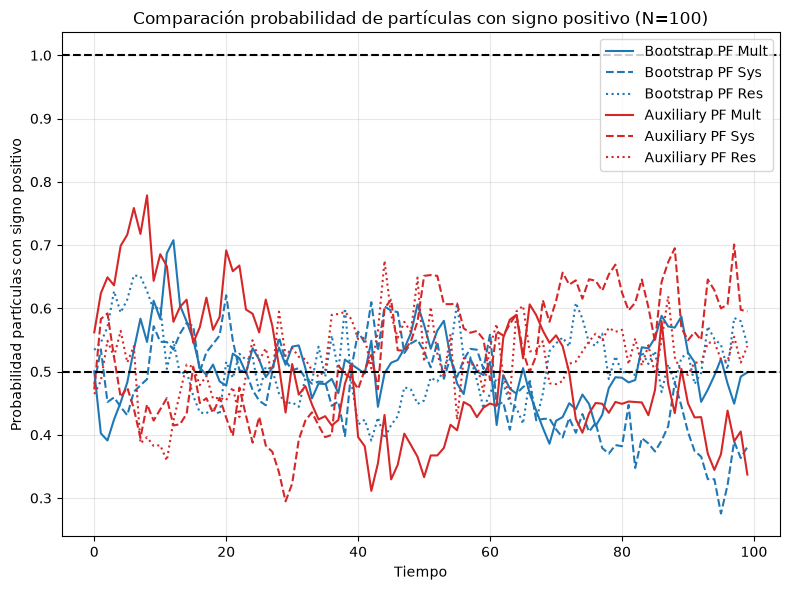

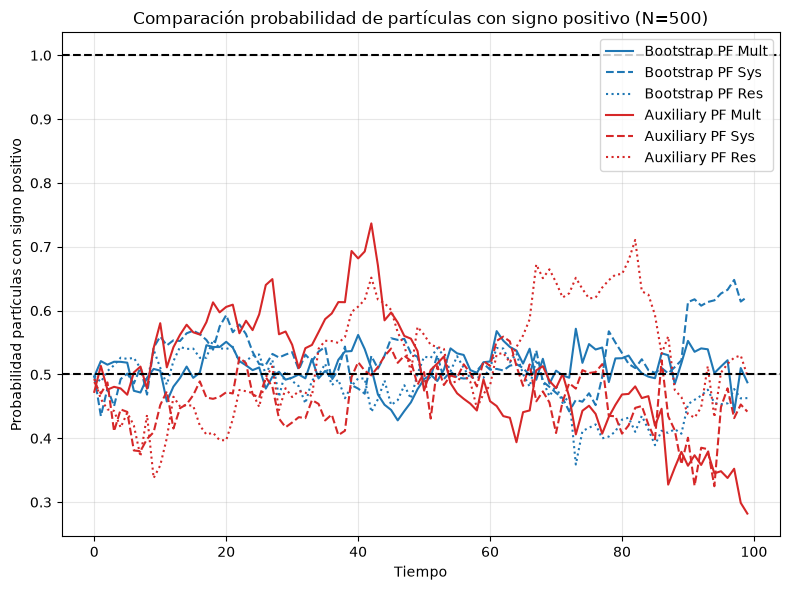

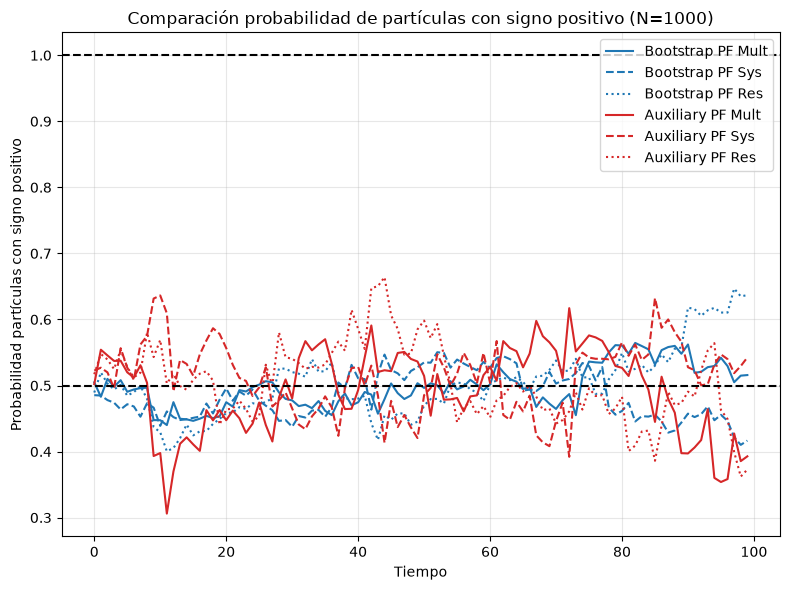

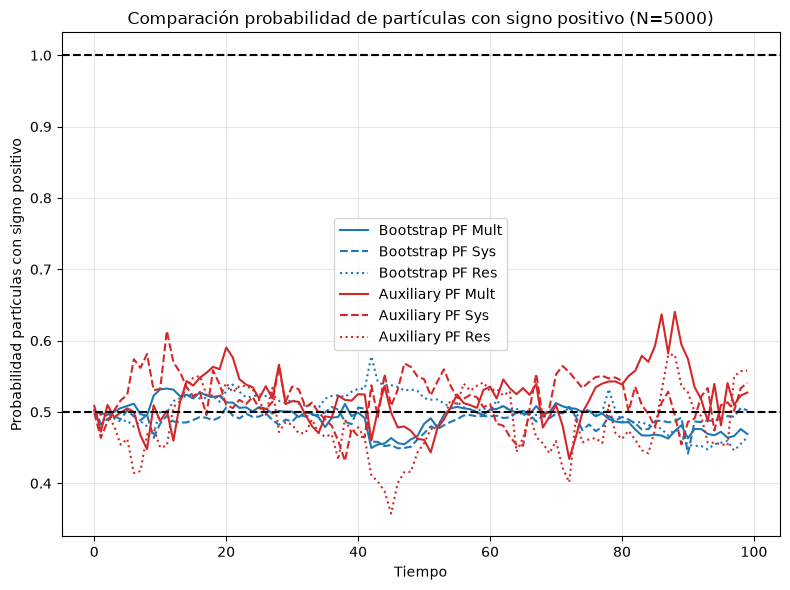

In [13]:
from plot_probabilities import plot_probs

N_particles = [50, 100, 500, 1000, 5000]

for N_part in N_particles:
    # Probabilidad partículas positivas
    plot_probs(
        {
        "Bootstrap PF Mult": mean_results_bpf_mult[N_part]["mean"]["Positive_probability"],
        "Bootstrap PF Sys": mean_results_bpf_sys[N_part]["mean"]["Positive_probability"],
        "Bootstrap PF Res": mean_results_bpf_res[N_part]["mean"]["Positive_probability"],
        "Auxiliary PF Mult": mean_results_apf_mult[N_part]["mean"]["Positive_probability"],
        "Auxiliary PF Sys": mean_results_apf_sys[N_part]["mean"]["Positive_probability"],
        "Auxiliary PF Res": mean_results_apf_res[N_part]["mean"]["Positive_probability"]
        }, N_part
    )

En general, se tiene que para el APF, se tiene una mayor probabilidad de perder alguna de las dos modas del modelo o más bien de que una de las modas pese más. Sin embargo, la diferencia con el BPF se reduce a medida que aumenta el número de partículas. Además a medida que aumenta el número de partículas, las probabilidades de ambas modas se igualan.

Por último, cabe destacar que a la hora de estimar el estado si se tienen dos grupos partículas en ambas modas cuyos pesos suman una cantidad parecida, normalmente se predecirá un estado nulo. Para reflejar este hecho, se va a representar los resultados para una de las simulaciones en concreto.

C:\Users\usuario\AppData\Local\Temp\ipykernel_12424\3380356145.py:6: RuntimeWarning: invalid value encountered in sqrt
  sqrt_y_obs =np.sqrt(y_obs)


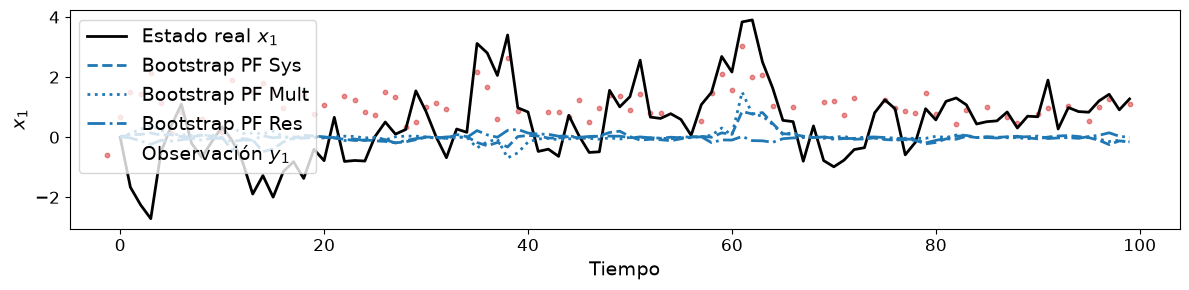

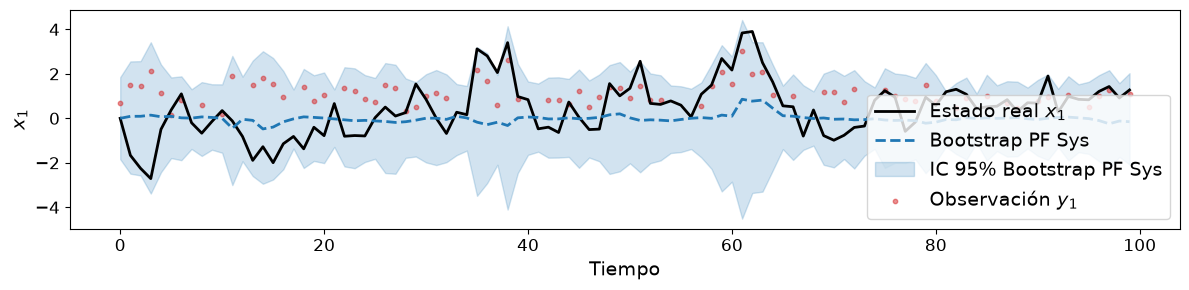

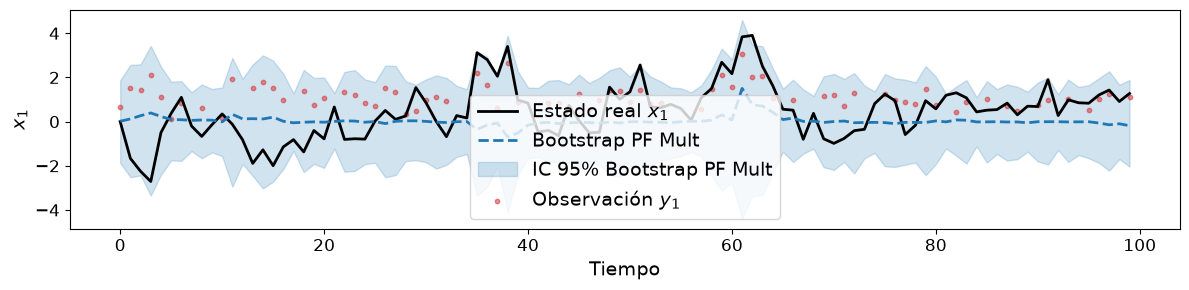

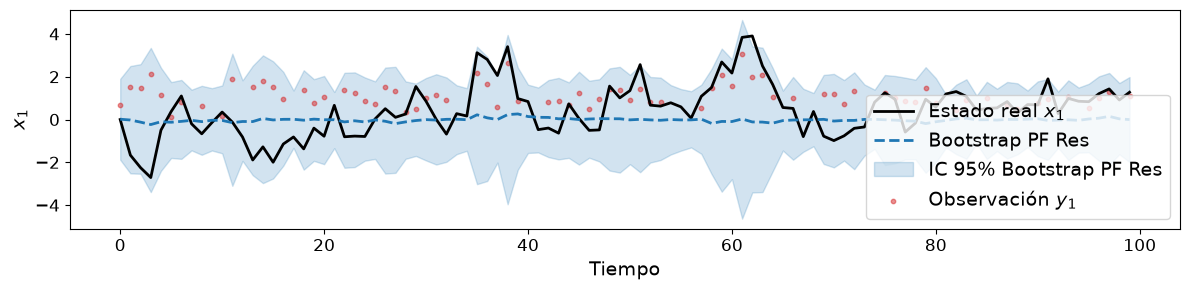

In [4]:
i = 4

x_true = results_bpf_5000_N["Bootstrap PF Systematic"][i]["x_true"]
y_obs = results_bpf_5000_N["Bootstrap PF Systematic"][i]["y_obs"]

sqrt_y_obs =np.sqrt(y_obs)

for j in range(len(sqrt_y_obs)):
    if sqrt_y_obs[j] == "nan":
        sqrt_y_obs[j] = 0.0

plot_results(x_true, sqrt_y_obs,
    {
        "Bootstrap PF Sys": results_bpf_1000_N["Bootstrap PF Systematic"][i]["est"]["estimates"],
        "Bootstrap PF Mult": results_bpf_1000_N["Bootstrap PF Multinomial"][i]["est"]["estimates"],
        "Bootstrap PF Res": results_bpf_1000_N["Bootstrap PF Residual"][i]["est"]["estimates"]
    }, x_title="Tiempo", plot_title="Evolución del estado estimado"
)

plot_results(x_true, sqrt_y_obs, 
             {"Bootstrap PF Sys": results_bpf_1000_N["Bootstrap PF Systematic"][i]["est"]["estimates"]
              }, x_title="Tiempo", plot_title="Evolución del estado estimado", confidence_intervals={
                  "Bootstrap PF Sys": results_bpf_1000_N["Bootstrap PF Systematic"][i]["est"]["intervals"]
              })

plot_results(x_true, sqrt_y_obs, 
             {"Bootstrap PF Mult": results_bpf_1000_N["Bootstrap PF Multinomial"][i]["est"]["estimates"]
              }, x_title="Tiempo", plot_title="Evolución del estado estimado", confidence_intervals={
                  "Bootstrap PF Mult": results_bpf_1000_N["Bootstrap PF Multinomial"][i]["est"]["intervals"]
              })

plot_results(x_true, sqrt_y_obs, 
             {"Bootstrap PF Res": results_bpf_1000_N["Bootstrap PF Residual"][i]["est"]["estimates"]
              }, x_title="Tiempo", plot_title="Evolución del estado estimado", confidence_intervals={
                  "Bootstrap PF Res": results_bpf_1000_N["Bootstrap PF Residual"][i]["est"]["intervals"]
              })


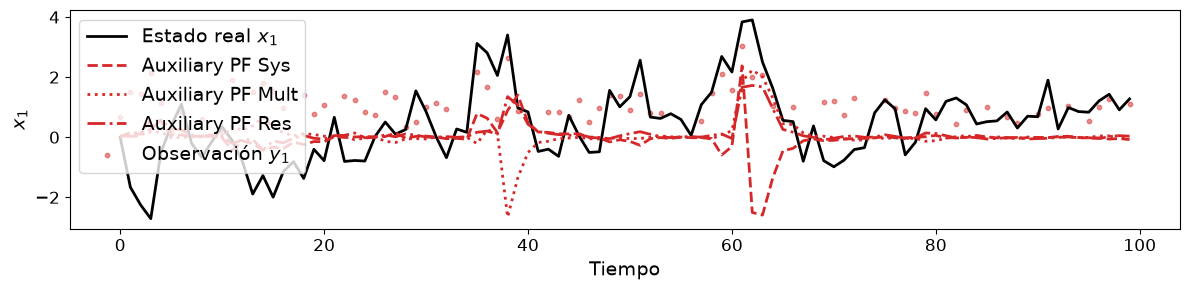

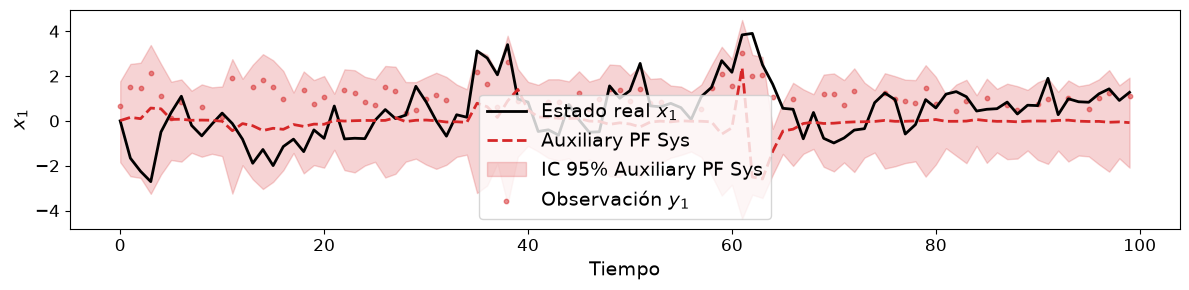

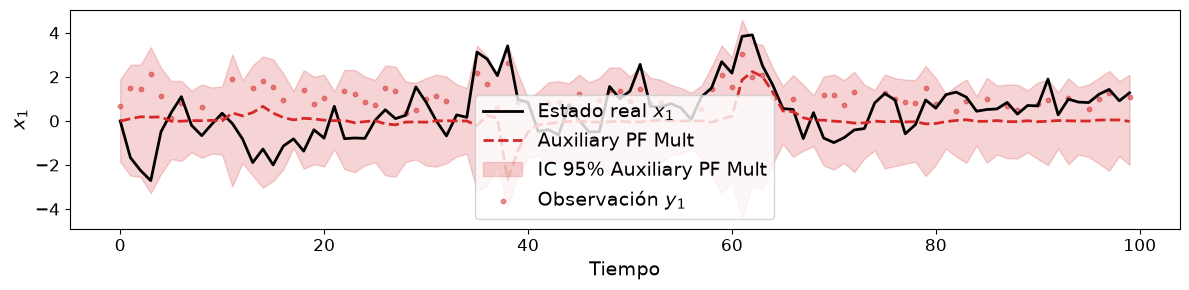

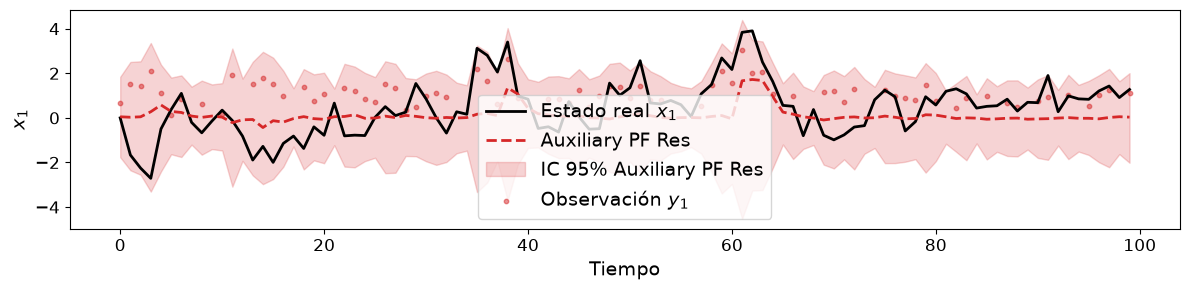

In [5]:
plot_results(x_true, sqrt_y_obs,
    {
        "Auxiliary PF Sys": results_apf_1000_N["Auxiliary PF Systematic"][i]["est"]["estimates"],
        "Auxiliary PF Mult": results_apf_1000_N["Auxiliary PF Multinomial"][i]["est"]["estimates"],
        "Auxiliary PF Res": results_apf_1000_N["Auxiliary PF Residual"][i]["est"]["estimates"]
    }, x_title="Tiempo", plot_title="Evolución del estado estimado"
)

plot_results(x_true, sqrt_y_obs, 
             {"Auxiliary PF Sys": results_apf_1000_N["Auxiliary PF Systematic"][i]["est"]["estimates"]
              }, x_title="Tiempo", plot_title="Evolución del estado estimado", confidence_intervals={
                  "Auxiliary PF Sys": results_apf_1000_N["Auxiliary PF Systematic"][i]["est"]["intervals"]
              })

plot_results(x_true, sqrt_y_obs, 
             {"Auxiliary PF Mult": results_apf_1000_N["Auxiliary PF Multinomial"][i]["est"]["estimates"]
              }, x_title="Tiempo", plot_title="Evolución del estado estimado", confidence_intervals={
                  "Auxiliary PF Mult": results_apf_1000_N["Auxiliary PF Multinomial"][i]["est"]["intervals"]
              })

plot_results(x_true, sqrt_y_obs, 
             {"Auxiliary PF Res": results_apf_1000_N["Auxiliary PF Residual"][i]["est"]["estimates"]
              }, x_title="Tiempo", plot_title="Evolución del estado estimado", confidence_intervals={
                  "Auxiliary PF Res": results_apf_1000_N["Auxiliary PF Residual"][i]["est"]["intervals"]
              })


En estos resultado, se observa, sobre todo al final de la simulación como la mayoría de los filtrados estimar un estado situado en el valor nulo. A continuación, se va a representar la distribución de las partículas a lo largo del tiempo.

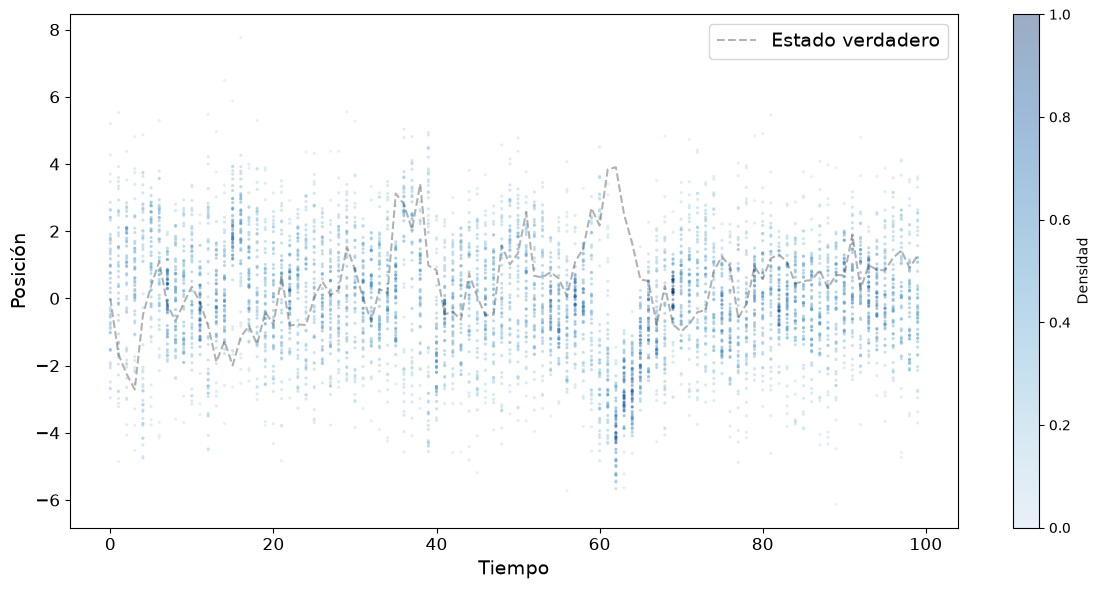

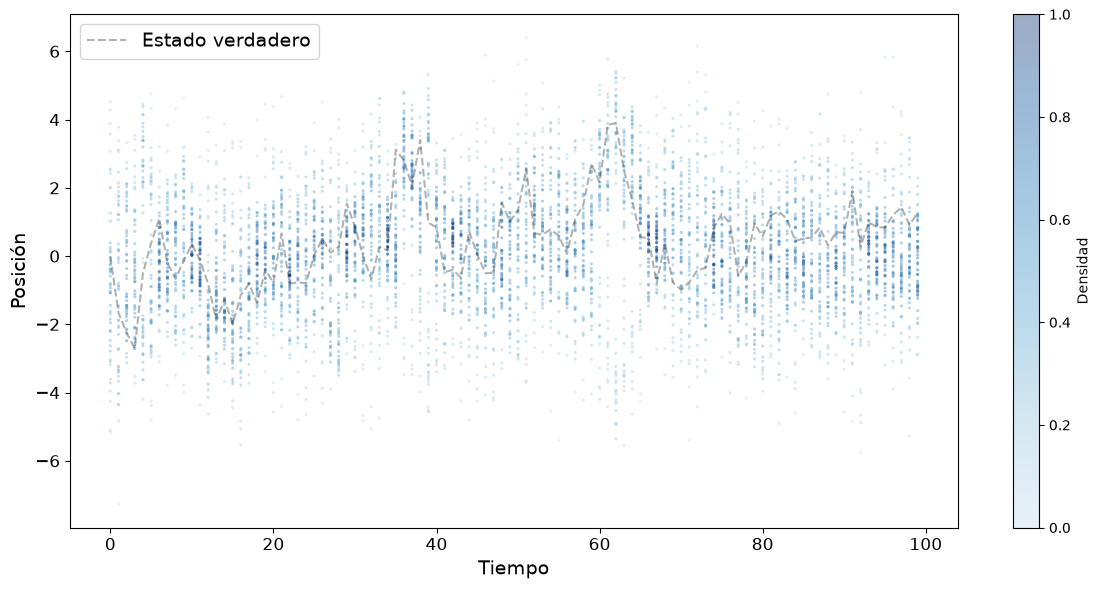

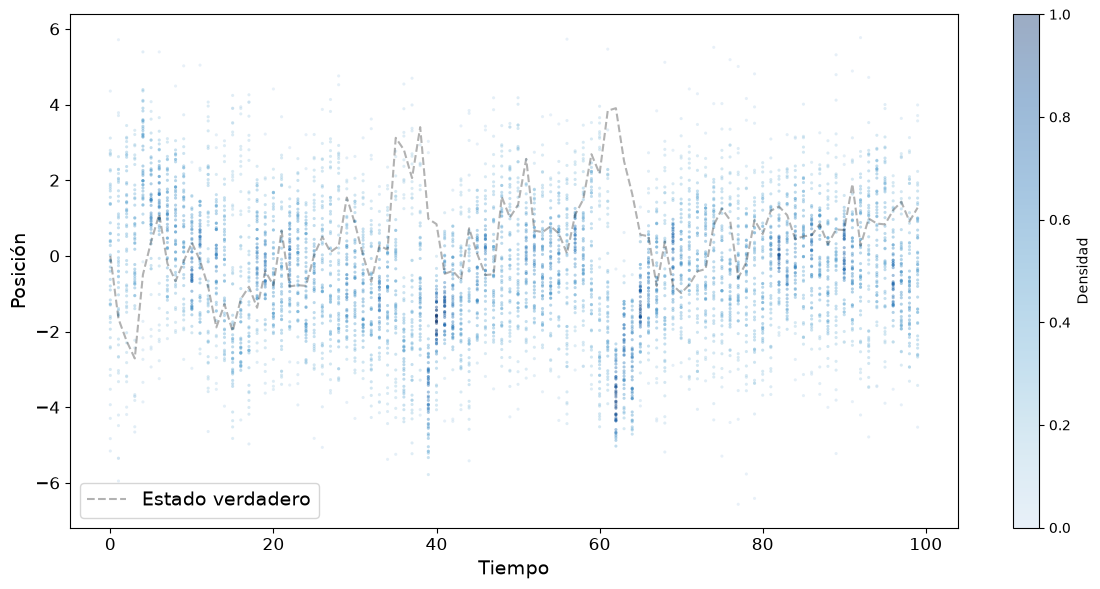

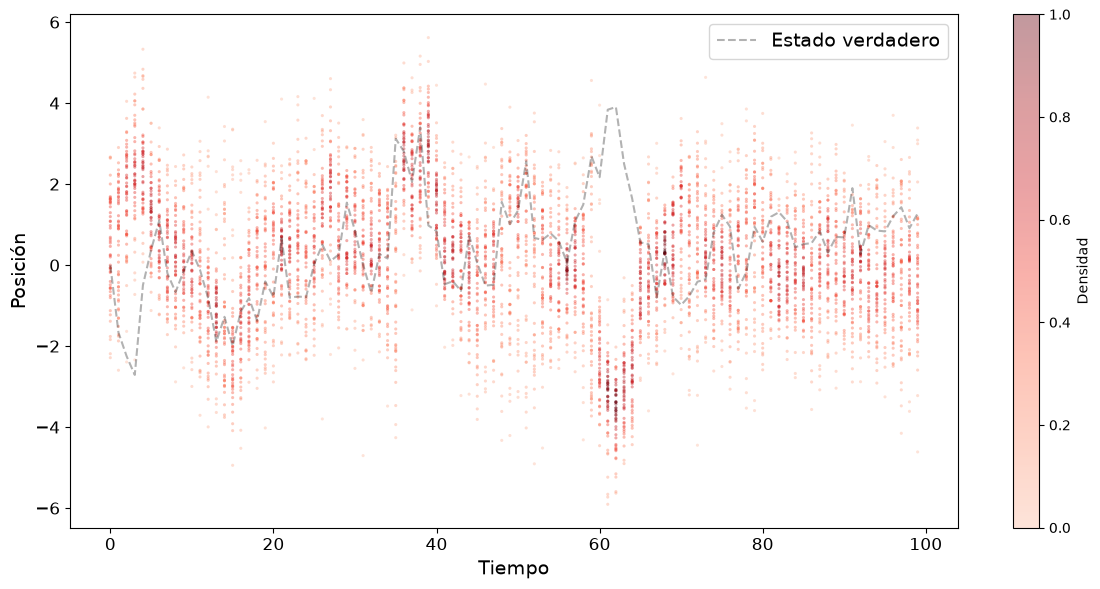

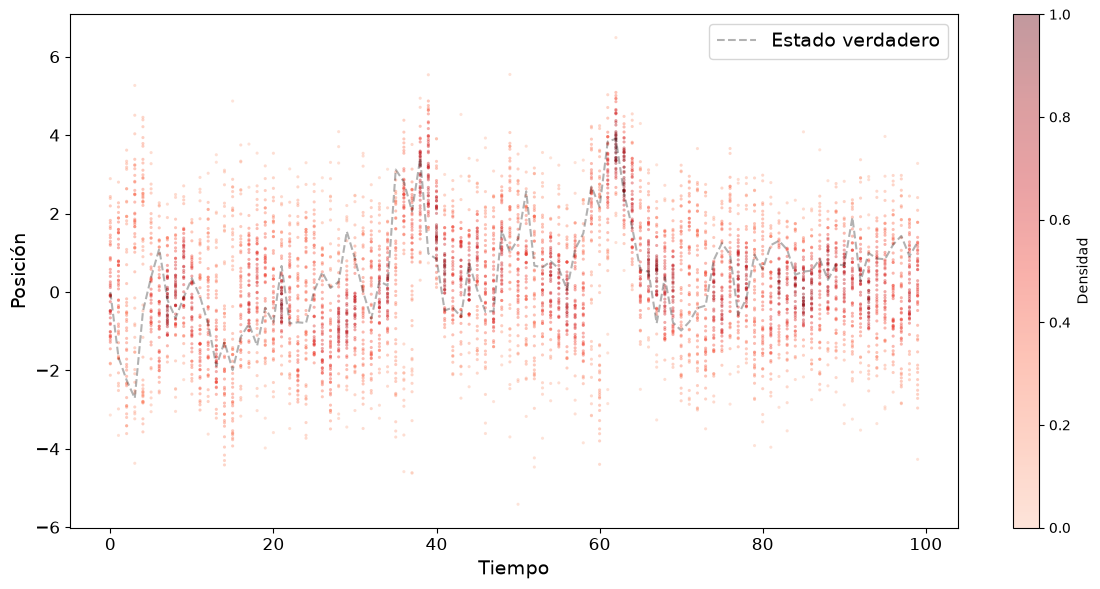

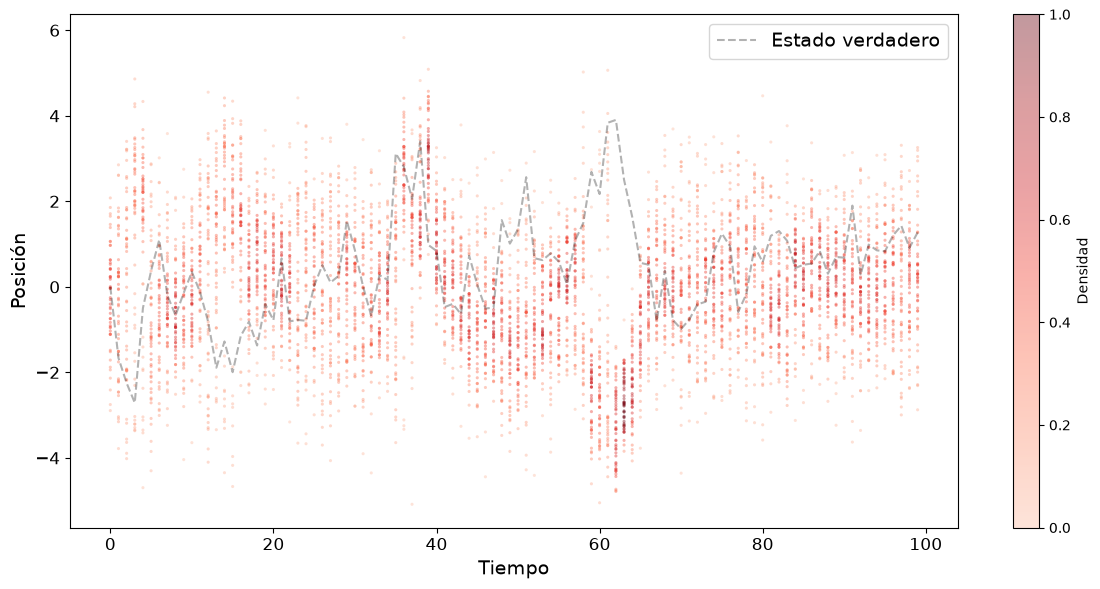

In [6]:
from particles_distribution import plot_particles_distribution

i = 4

plot_particles_distribution(results_bpf_50_N["Bootstrap PF Multinomial"][i]["est"]["particles_pre_resampling"], "Bootstrap PF Multinomial", "BPF", True, x_true)
plot_particles_distribution(results_bpf_50_N["Bootstrap PF Systematic"][i]["est"]["particles_pre_resampling"], "Bootstrap PF Systematic", "BPF", True, x_true)
plot_particles_distribution(results_bpf_50_N["Bootstrap PF Residual"][i]["est"]["particles_pre_resampling"], "Bootstrap PF Residual", "BPF", True, x_true)

plot_particles_distribution(results_apf_50_N["Auxiliary PF Multinomial"][i]["est"]["particles_pre_resampling"], "Auxiliary PF Multinomial", "APF", True, x_true)
plot_particles_distribution(results_apf_50_N["Auxiliary PF Systematic"][i]["est"]["particles_pre_resampling"], "Auxiliary PF Systematic", "APF", True, x_true)
plot_particles_distribution(results_apf_50_N["Auxiliary PF Residual"][i]["est"]["particles_pre_resampling"], "Auxiliary PF Residual", "APF", True, x_true)

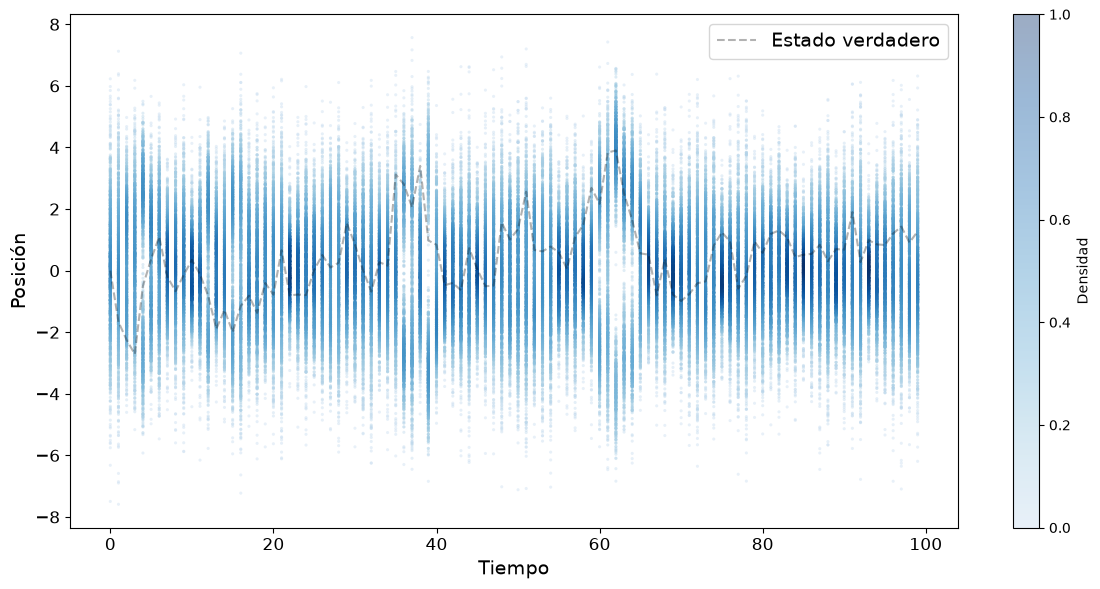

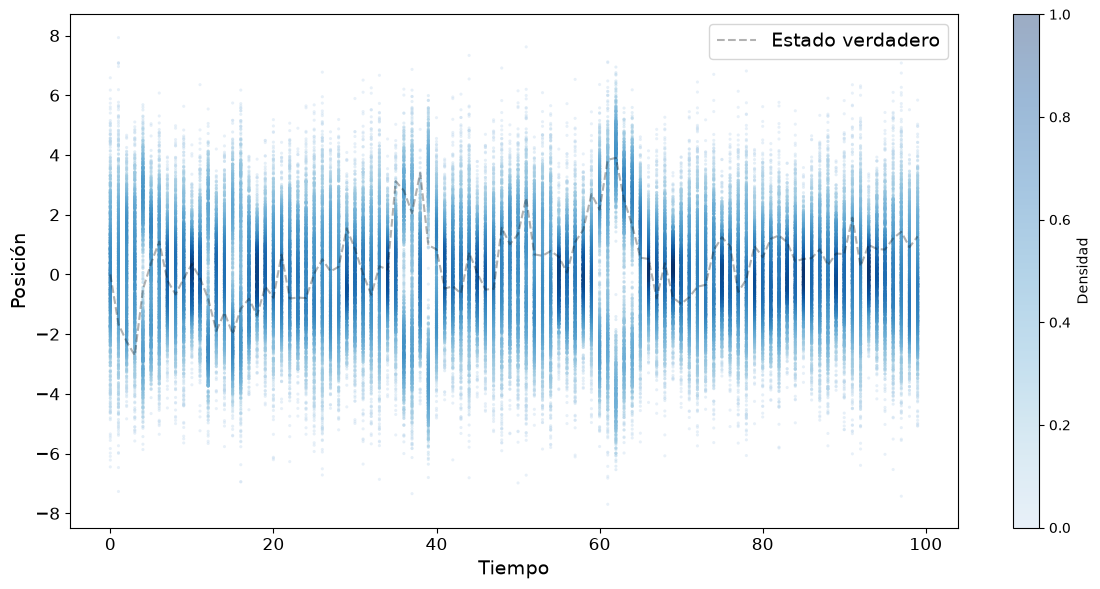

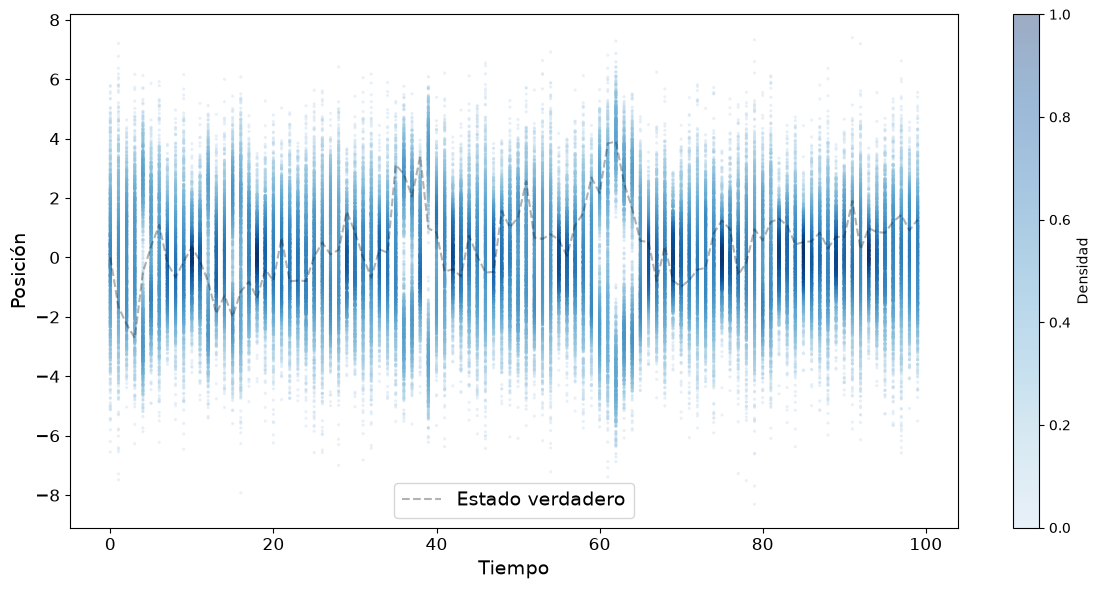

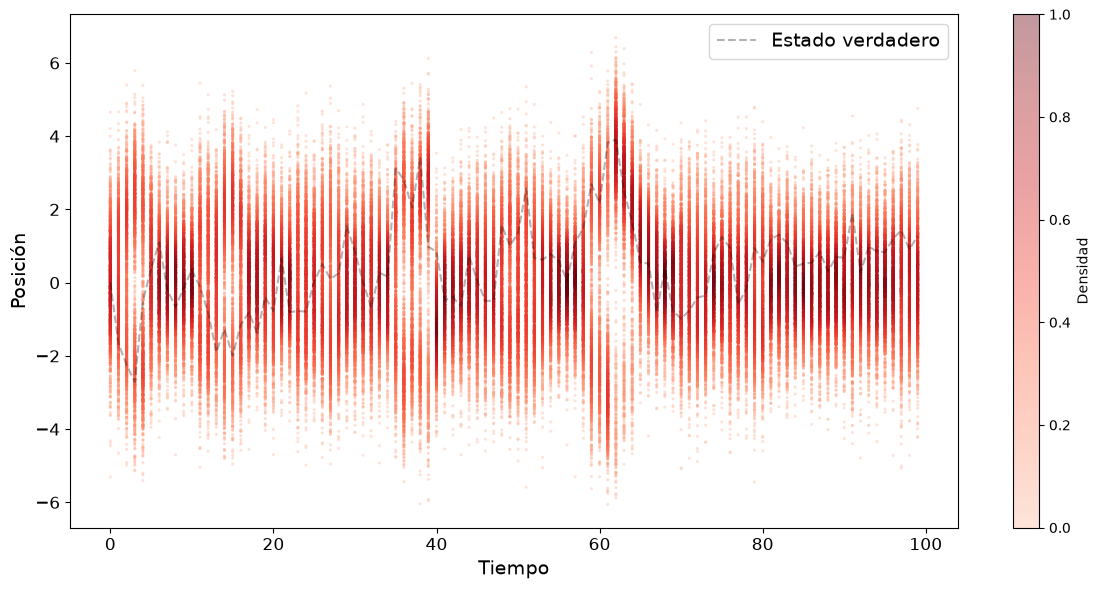

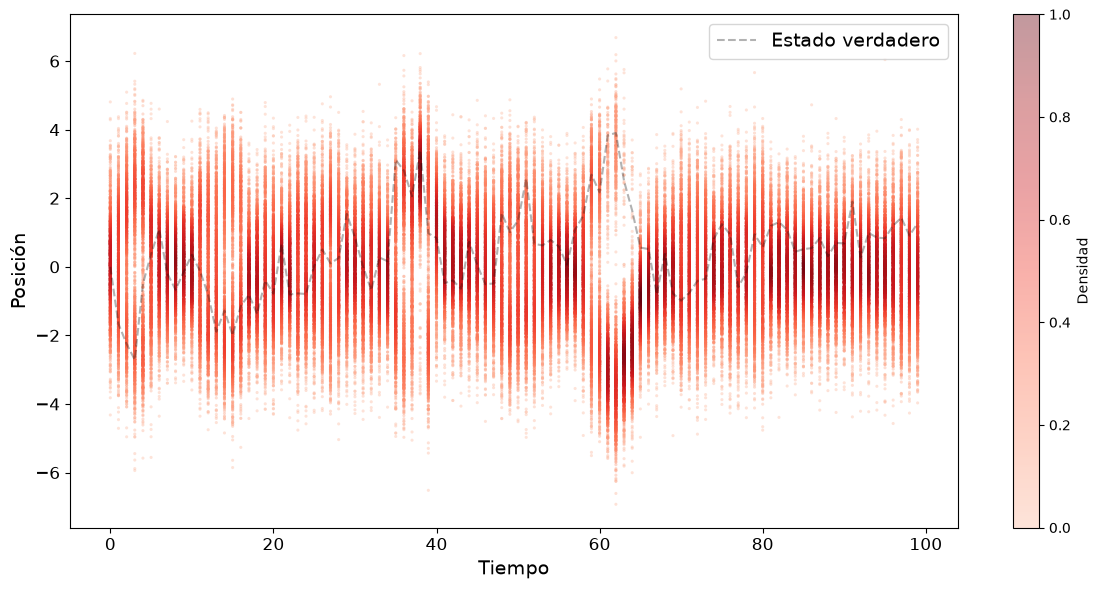

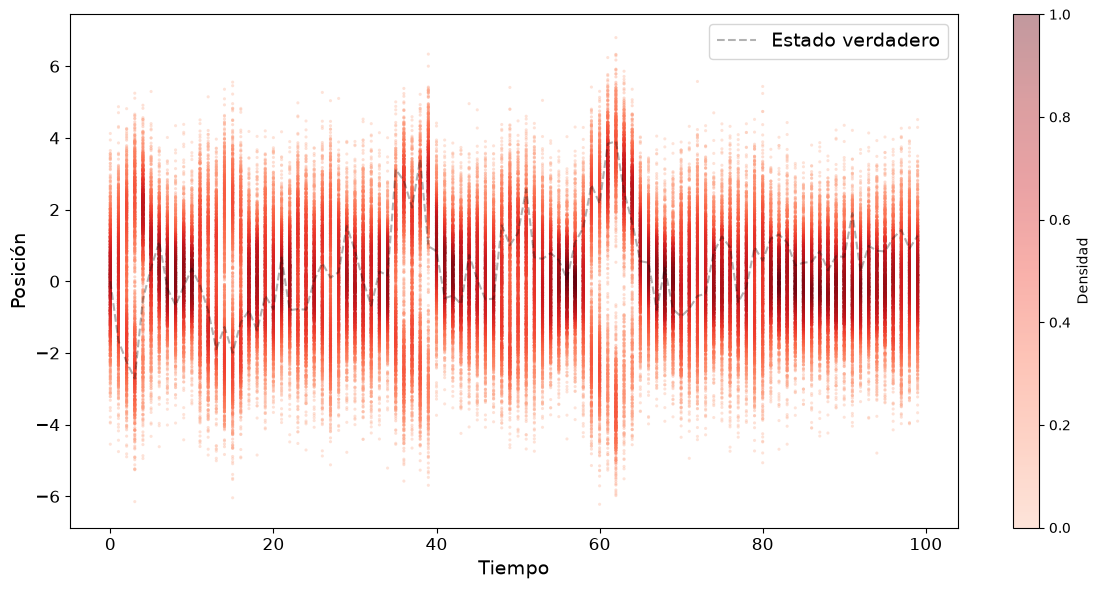

In [7]:
from particles_distribution import plot_particles_distribution

i = 4

plot_particles_distribution(results_bpf_1000_N["Bootstrap PF Multinomial"][i]["est"]["particles_pre_resampling"], "Bootstrap PF Multinomial", "BPF", True, x_true)
plot_particles_distribution(results_bpf_1000_N["Bootstrap PF Systematic"][i]["est"]["particles_pre_resampling"], "Bootstrap PF Systematic", "BPF", True, x_true)
plot_particles_distribution(results_bpf_1000_N["Bootstrap PF Residual"][i]["est"]["particles_pre_resampling"], "Bootstrap PF Residual", "BPF", True, x_true)

plot_particles_distribution(results_apf_1000_N["Auxiliary PF Multinomial"][i]["est"]["particles_pre_resampling"], "Auxiliary PF Multinomial", "APF", True, x_true)
plot_particles_distribution(results_apf_1000_N["Auxiliary PF Systematic"][i]["est"]["particles_pre_resampling"], "Auxiliary PF Systematic", "APF", True, x_true)
plot_particles_distribution(results_apf_1000_N["Auxiliary PF Residual"][i]["est"]["particles_pre_resampling"], "Auxiliary PF Residual", "APF", True, x_true)


Por lo tanto, en esta últimas gráfica se aprecia como, en general el filtrado permite mantenr las dos modas, aunque en el BPF de manera más efectiva respecto al APF. El hecho de mantener estas modas (que son la posibles regiones del estado) implica que el estado predicho resulte en muchas situaciones el estado nulo.

### MCMC 
(hecho para N=1000 no hay mucho cambio)

In [64]:
with open("exp_24.pkl", "rb") as file:
    results_bpf_mcmc = pickle.load(file)

with open("exp_25.pkl", "rb") as file:
    results_apf_mcmc = pickle.load(file)    

In [ ]:
from N_eff_ancestors import average_N_eff_anc

N_particles = [1000]
N_simulations = 10

results = {
    1000: results_bpf_mcmc
}

bpf_mult_mcmc = dict.fromkeys(N_particles)
bpf_sys_mcmc = dict.fromkeys(N_particles)
bpf_res_mcmc = dict.fromkeys(N_particles)

for N_part in N_particles:

    mean_mult, std_mult, mean_sys, std_sys, mean_res, std_res = average_N_eff_anc(results[N_part], N_simulations, N_part, "Bootstrap")

    bpf_mult_mcmc[N_part] = {"mean": mean_mult, "std": std_mult}
    bpf_sys_mcmc[N_part] = {"mean": mean_sys, "std": std_sys}
    bpf_res_mcmc[N_part] = {"mean": mean_res, "std": std_res}


Multiomial con 1000 partículas: 0.231212517742666 +/- 0.01875764679519964
Systematic con 1000 partículas: 0.30268976729015745 +/- 0.029410468400287063
Residual con 1000 partículas: 0.28619150654537273 +/- 0.022256299748439883



In [77]:
N_particles = [1000]

for N_part in N_particles:
    print("MCMC")
    print(f"Multiomial con {N_part} partículas: {bpf_mult_mcmc[N_part]["mean"]} +/- {bpf_mult_mcmc[N_part]["std"]}")
    print(f"Systematic con {N_part} partículas: {bpf_sys_mcmc[N_part]["mean"]} +/- {bpf_sys_mcmc[N_part]["std"]}")
    print(f"Residual con {N_part} partículas: {bpf_res_mcmc[N_part]["mean"]} +/- {bpf_res_mcmc[N_part]["std"]}")
    print("")

    print("No MCMC")
    print(f"Multiomial con {N_part} partículas: {bpf_mult[N_part]["mean"]} +/- {bpf_mult[N_part]["std"]}")
    print(f"Systematic con {N_part} partículas: {bpf_sys[N_part]["mean"]} +/- {bpf_sys[N_part]["std"]}")
    print(f"Residual con {N_part} partículas: {bpf_res[N_part]["mean"]} +/- {bpf_res[N_part]["std"]}")
    print("")

MCMC
Multiomial con 1000 partículas: 0.231212517742666 +/- 0.01875764679519964
Systematic con 1000 partículas: 0.30268976729015745 +/- 0.029410468400287063
Residual con 1000 partículas: 0.28619150654537273 +/- 0.022256299748439883

No MCMC
Multiomial con 1000 partículas: 0.22890429725958433 +/- 0.015374216535707535
Systematic con 1000 partículas: 0.29535060451875716 +/- 0.02321190018569393
Residual con 1000 partículas: 0.2780744813922064 +/- 0.02242357058327327



In [80]:
from N_eff_ancestors import average_N_eff_anc

N_particles = [1000]
N_simulations = 10

results = {
    1000: results_apf_mcmc
}

apf_mult_mcmc = dict.fromkeys(N_particles)
apf_sys_mcmc = dict.fromkeys(N_particles)
apf_res_mcmc = dict.fromkeys(N_particles)

for N_part in N_particles:

    mean_mult, std_mult, mean_sys, std_sys, mean_res, std_res = average_N_eff_anc(results[N_part], N_simulations, N_part, "Auxiliary")

    apf_mult_mcmc[N_part] = {"mean": mean_mult, "std": std_mult}
    apf_sys_mcmc[N_part] = {"mean": mean_sys, "std": std_sys}
    apf_res_mcmc[N_part] = {"mean": mean_res, "std": std_res}

In [83]:
N_particles = [1000]

for N_part in N_particles:
    print("MCMC")
    print(f"Multiomial con {N_part} partículas: {apf_mult_mcmc[N_part]["mean"]} +/- {apf_mult_mcmc[N_part]["std"]}")
    print(f"Systematic con {N_part} partículas: {apf_sys_mcmc[N_part]["mean"]} +/- {apf_sys_mcmc[N_part]["std"]}")
    print(f"Residual con {N_part} partículas: {apf_res_mcmc[N_part]["mean"]} +/- {apf_res_mcmc[N_part]["std"]}")
    print("")

    print("No MCMC")
    print(f"Multiomial con {N_part} partículas: {apf_mult[N_part]["mean"]} +/- {apf_mult[N_part]["std"]}")
    print(f"Systematic con {N_part} partículas: {apf_sys[N_part]["mean"]} +/- {apf_sys[N_part]["std"]}")
    print(f"Residual con {N_part} partículas: {apf_res[N_part]["mean"]} +/- {apf_res[N_part]["std"]}")
    print("")

MCMC
Multiomial con 1000 partículas: 0.1485551394509017 +/- 0.024985192199121712
Systematic con 1000 partículas: 0.18347525812145804 +/- 0.033631725818288064
Residual con 1000 partículas: 0.16364120879423125 +/- 0.0260107177112523

No MCMC
Multiomial con 1000 partículas: 0.14821228671442124 +/- 0.018255986406030777
Systematic con 1000 partículas: 0.1887805287583854 +/- 0.02418362233800802
Residual con 1000 partículas: 0.1746839498511114 +/- 0.03385824422586736



In [84]:
from average_results import average_results

N_simul = 10
N_filt = 1
T = 100

bpf_sys_mcmc = average_results(results_bpf_mcmc["Bootstrap PF Systematic"], N_simul, N_filt, T)
bpf_mult_mcmc = average_results(results_bpf_mcmc["Bootstrap PF Multinomial"], N_simul, N_filt, T)
bpf_res_mcmc = average_results(results_bpf_mcmc["Bootstrap PF Residual"], N_simul, N_filt, T)

apf_sys_mcmc = average_results(results_apf_mcmc["Auxiliary PF Systematic"], N_simul, N_filt, T)
apf_mult_mcmc = average_results(results_apf_mcmc["Auxiliary PF Multinomial"], N_simul, N_filt, T)
apf_res_mcmc = average_results(results_apf_mcmc["Auxiliary PF Residual"], N_simul, N_filt, T)

c:\Users\usuario\Desktop\Particle_Filter\.venv\Lib\site-packages\numpy\_core\_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
c:\Users\usuario\Desktop\Particle_Filter\.venv\Lib\site-packages\numpy\_core\_methods.py:211: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


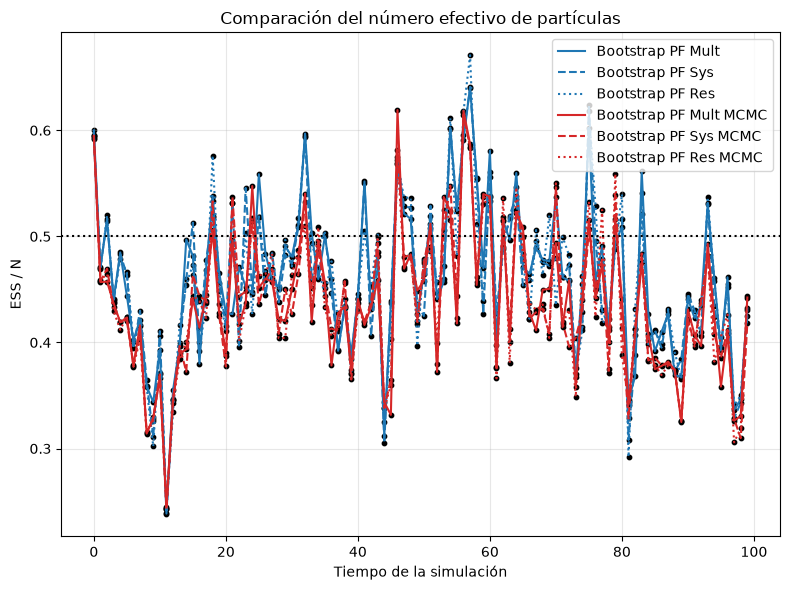

In [89]:
plot_ESS({
    "Bootstrap PF Mult": bpf_mult["mean"]["ESS"],
    "Bootstrap PF Sys": bpf_sys["mean"]["ESS"],
    "Bootstrap PF Res": bpf_res["mean"]["ESS"],
    "Bootstrap PF Mult MCMC": bpf_mult_mcmc["mean"]["ESS"],
    "Bootstrap PF Sys MCMC": bpf_sys_mcmc["mean"]["ESS"],
    "Bootstrap PF Res MCMC": bpf_res_mcmc["mean"]["ESS"],
}, 1000)

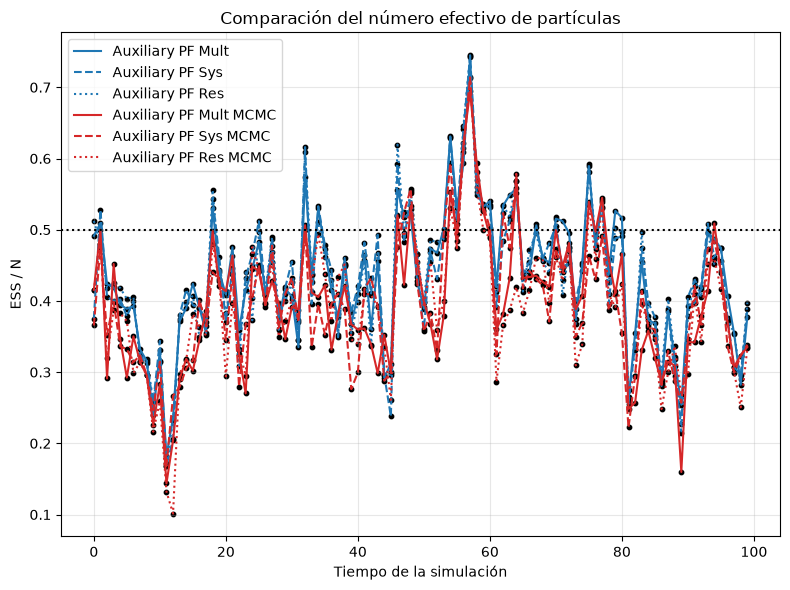

In [90]:
plot_ESS({
    "Auxiliary PF Mult": apf_mult["mean"]["ESS"],
    "Auxiliary PF Sys": apf_sys["mean"]["ESS"],
    "Auxiliary PF Res": apf_res["mean"]["ESS"],
    "Auxiliary PF Mult MCMC": apf_mult_mcmc["mean"]["ESS"],
    "Auxiliary PF Sys MCMC": apf_sys_mcmc["mean"]["ESS"],
    "Auxiliary PF Res MCMC": apf_res_mcmc["mean"]["ESS"],
}, 1000)

C:\Users\usuario\AppData\Local\Temp\ipykernel_15144\3853758045.py:6: RuntimeWarning: invalid value encountered in sqrt
  sqrt_y_obs =np.sqrt(y_obs)


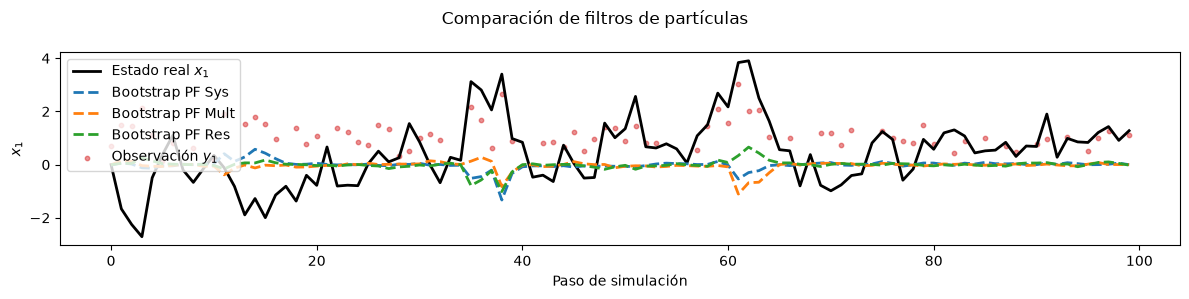

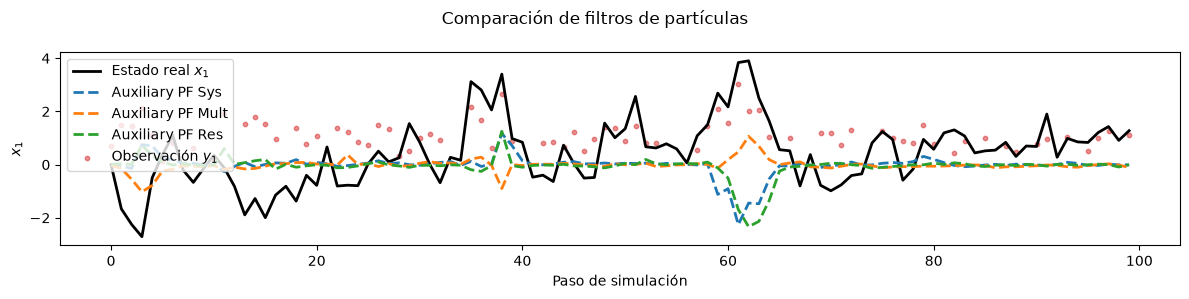

In [91]:
i = 4

x_true = results_bpf_mcmc["Bootstrap PF Systematic"][i]["x_true"]
y_obs = results_bpf_mcmc["Bootstrap PF Systematic"][i]["y_obs"]

sqrt_y_obs =np.sqrt(y_obs)

for j in range(len(sqrt_y_obs)):
    if sqrt_y_obs[j] == "nan":
        sqrt_y_obs[j] = 0.0

plot_results(x_true, sqrt_y_obs,
    {
        "Bootstrap PF Sys": results_bpf_mcmc["Bootstrap PF Systematic"][i]["est"]["estimates"],
        "Bootstrap PF Mult": results_bpf_mcmc["Bootstrap PF Multinomial"][i]["est"]["estimates"],
        "Bootstrap PF Res": results_bpf_mcmc["Bootstrap PF Residual"][i]["est"]["estimates"]
    }
)

plot_results(x_true, sqrt_y_obs,
    {
        "Auxiliary PF Sys": results_apf_mcmc["Auxiliary PF Systematic"][i]["est"]["estimates"],
        "Auxiliary PF Mult": results_apf_mcmc["Auxiliary PF Multinomial"][i]["est"]["estimates"],
        "Auxiliary PF Res": results_apf_mcmc["Auxiliary PF Residual"][i]["est"]["estimates"]
    }
)

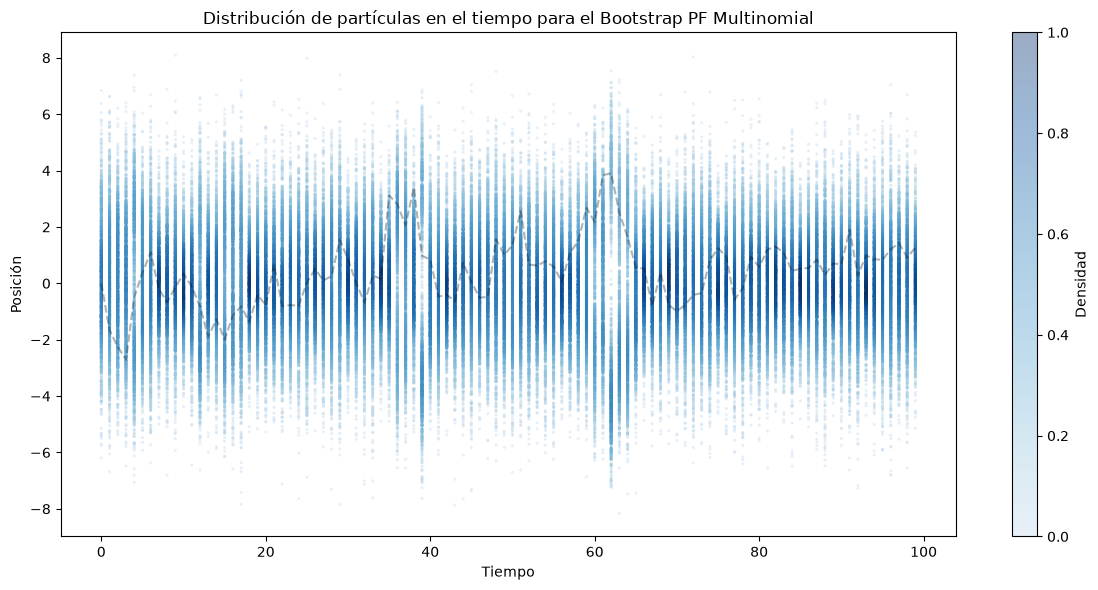

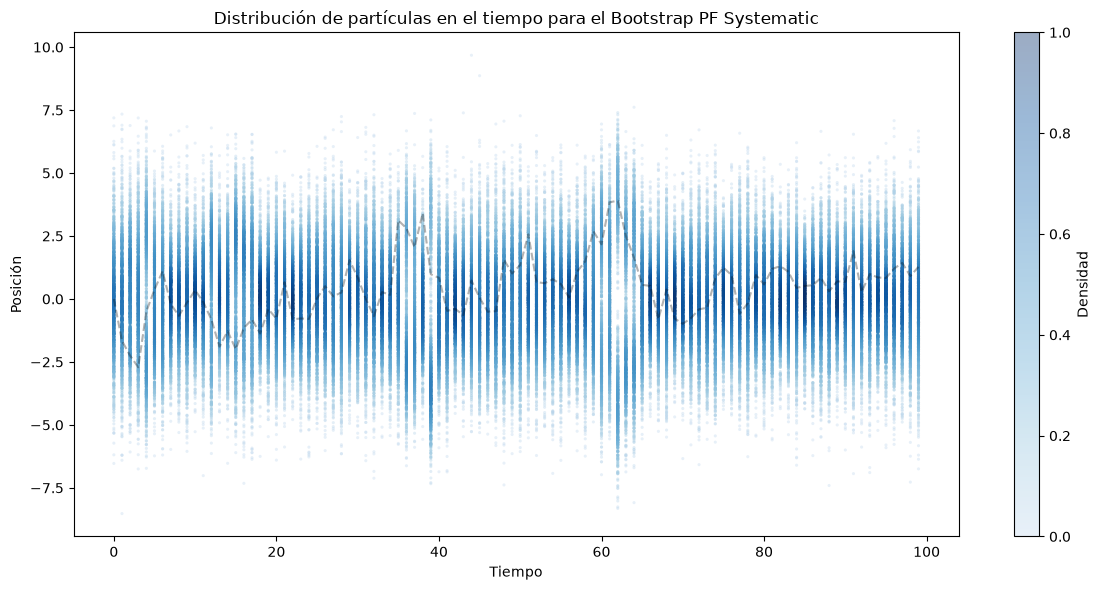

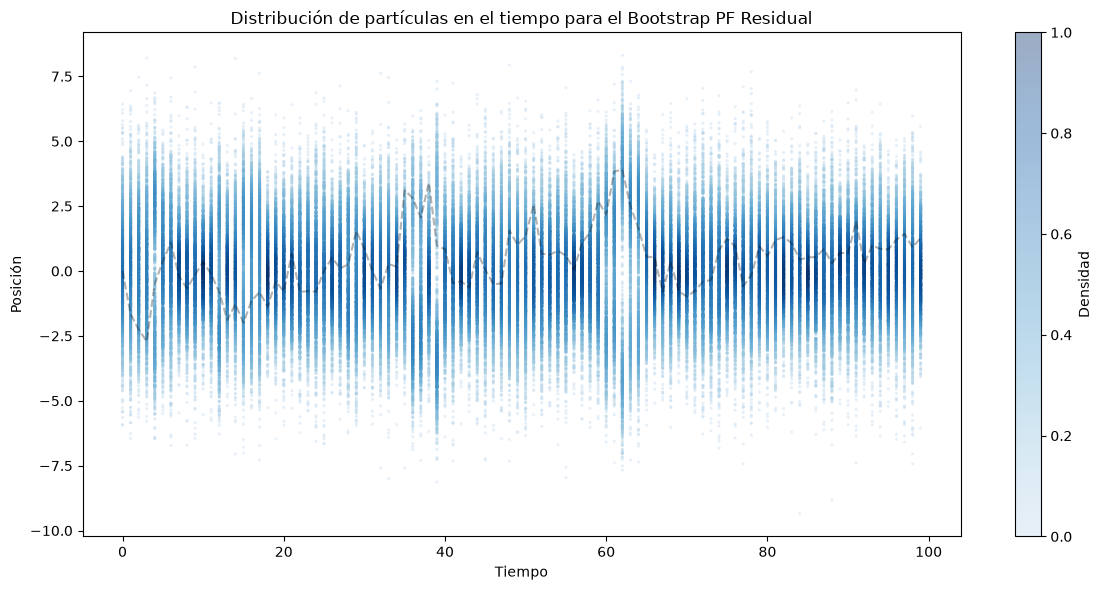

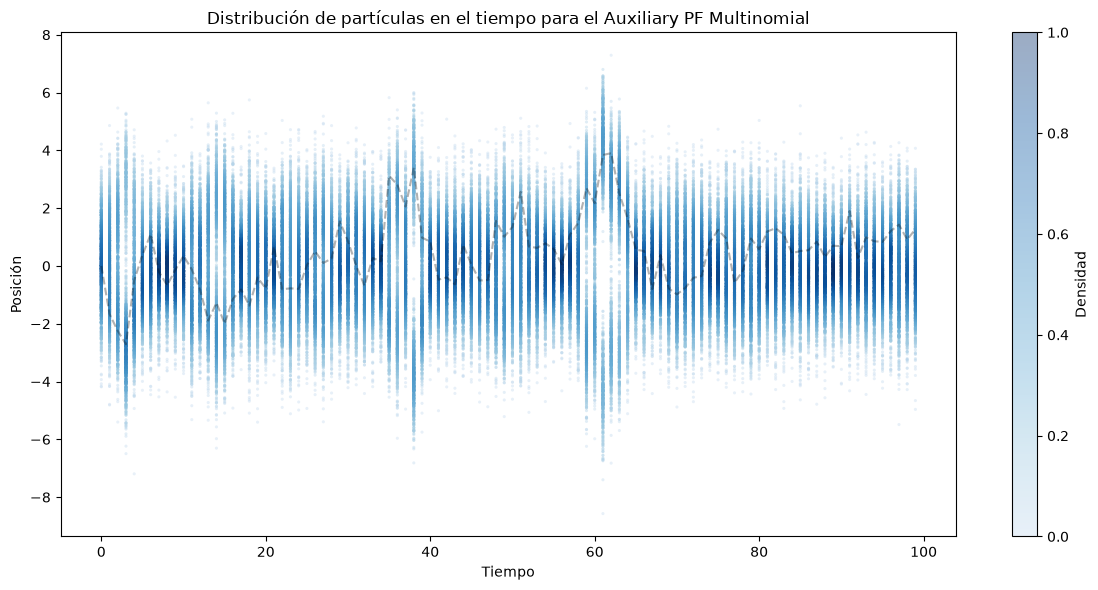

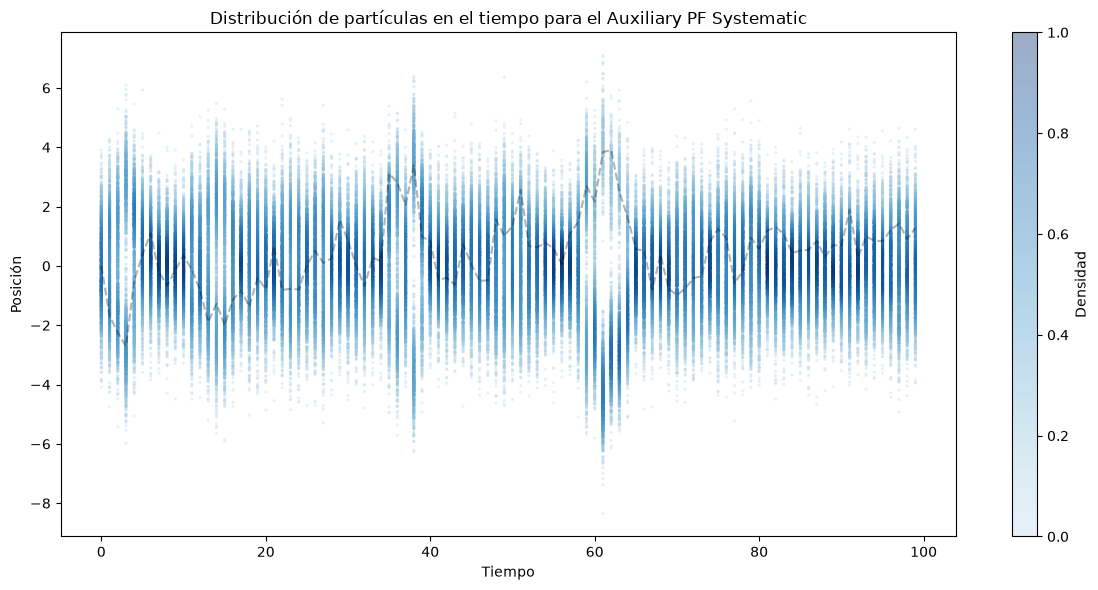

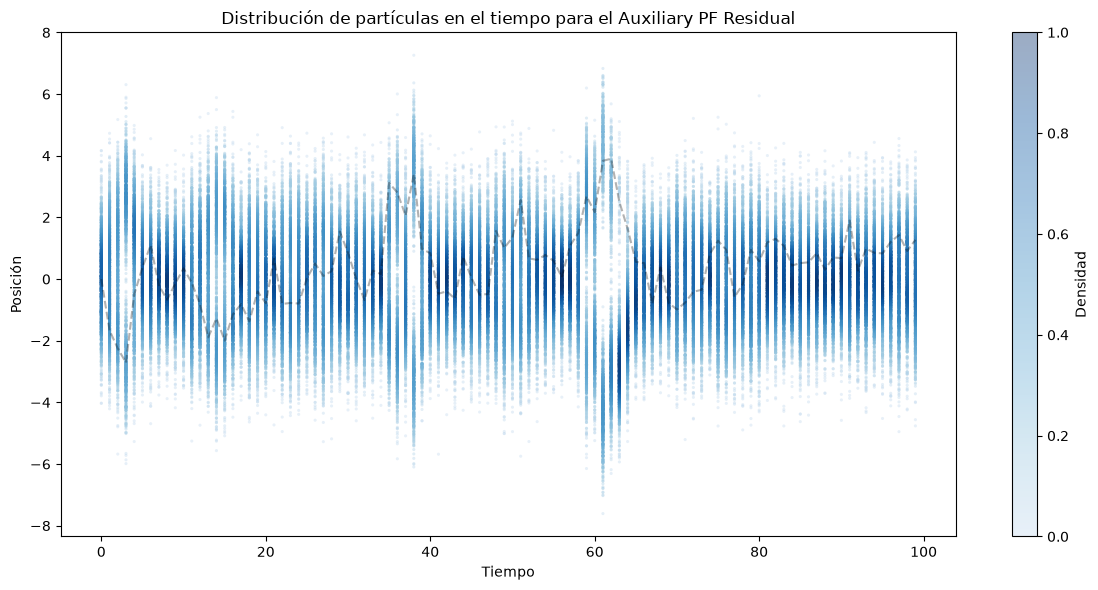

In [92]:
i = 4

plot_particles_distribution(results_bpf_mcmc["Bootstrap PF Multinomial"][i]["est"]["particles_pre_resampling"], "Bootstrap PF Multinomial", True, x_true)
plot_particles_distribution(results_bpf_mcmc["Bootstrap PF Systematic"][i]["est"]["particles_pre_resampling"], "Bootstrap PF Systematic", True, x_true)
plot_particles_distribution(results_bpf_mcmc["Bootstrap PF Residual"][i]["est"]["particles_pre_resampling"], "Bootstrap PF Residual", True, x_true)

plot_particles_distribution(results_apf_mcmc["Auxiliary PF Multinomial"][i]["est"]["particles_pre_resampling"], "Auxiliary PF Multinomial", True, x_true)
plot_particles_distribution(results_apf_mcmc["Auxiliary PF Systematic"][i]["est"]["particles_pre_resampling"], "Auxiliary PF Systematic", True, x_true)
plot_particles_distribution(results_apf_mcmc["Auxiliary PF Residual"][i]["est"]["particles_pre_resampling"], "Auxiliary PF Residual", True, x_true)